# CPU visualization

Visualization notebook generated for the visualization-ready analysis outputs. It keeps datasets separated, uses units in axis labels, includes boxplots where sample-level rows are available, and treats accuracy only for datasets that expose correctness.

In [1]:
from pathlib import Path
import json
import itertools
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == "notebooks" else Path.cwd().resolve()
FIGURES_ROOT = ROOT / "figures" / "visualization_ready"
FIGURES_ROOT.mkdir(parents=True, exist_ok=True)

DATASETS_WITH_ACCURACY = {"mmlu", "hellaswag", "gsm8k"}
DOLLY_LIKE_DATASETS = {"dolly"}

UNIT_LABELS = {
    "accuracy": "Accuracy (fraction correct)",
    "accuracy_percent": "Accuracy (%)",
    "latency_ms": "End-to-end latency (ms)",
    "ttft_ms": "Time to first token, TTFT (ms)",
    "tokens_per_sec": "Generation throughput (tokens/s)",
    "sustained_tokens_per_sec": "Sequential sustained throughput (tokens/s)",
    "samples_per_sec": "Sequential sustained rate (samples/s)",
    "output_tokens": "Output length (tokens)",
    "cpu_percent_avg": "Average CPU utilization (%)",
    "cpu_percent_peak": "Peak CPU utilization (%)",
    "cpu_percent": "CPU utilization (%)",
    "ram_used_mb_peak": "Peak system RAM used (MB)",
    "ram_used_mb": "System RAM used (MB)",
    "process_ram_mb_peak": "Peak server process RAM (MB)",
    "process_ram_mb": "Server process RAM (MB)",
    "temp_c_avg": "Average temperature (°C)",
    "temp_c_peak": "Peak temperature (°C)",
    "temperature_c": "Temperature (°C)",
    "gpu_util_percent_avg": "Average GPU utilization (%)",
    "gpu_util_percent_peak": "Peak GPU utilization (%)",
    "gpu_util_percent": "GPU utilization (%)",
    "vram_used_mb_peak": "Peak VRAM used (MB)",
    "vram_used_mb": "VRAM used (MB)",
    "power_w_avg": "Average GPU power draw (W)",
    "power_w_peak": "Peak GPU power draw (W)",
    "power_w": "GPU power draw (W)",
    "energy_j": "Estimated energy per sample (J)",
    "energy_per_token_j": "Estimated energy per output token (J/token)",
    "tokens_per_joule": "Output tokens per joule (tokens/J)",
    "accuracy_per_second": "Accuracy per second (fraction/s)",
    "accuracy_per_joule": "Accuracy per joule (fraction/J)",
}

HIGHER_IS_BETTER = {
    "accuracy", "accuracy_percent", "tokens_per_sec", "sustained_tokens_per_sec", "samples_per_sec",
    "tokens_per_joule", "accuracy_per_second", "accuracy_per_joule"
}

SUMMARY_METRICS_COMMON = [
    "accuracy", "latency_ms", "ttft_ms", "tokens_per_sec", "sustained_tokens_per_sec", "samples_per_sec",
    "cpu_percent_avg", "cpu_percent_peak", "ram_used_mb_peak", "process_ram_mb_peak", "temp_c_avg", "temp_c_peak",
    "gpu_util_percent_avg", "gpu_util_percent_peak", "vram_used_mb_peak", "power_w_avg", "power_w_peak",
    "energy_j", "energy_per_token_j", "tokens_per_joule", "accuracy_per_second", "accuracy_per_joule",
]

SAMPLE_METRICS_COMMON = [
    "latency_ms", "ttft_ms", "tokens_per_sec", "output_tokens",
    "cpu_percent_avg", "cpu_percent_peak", "ram_used_mb_peak", "process_ram_mb_peak", "temp_c_avg", "temp_c_peak",
    "gpu_util_percent_avg", "gpu_util_percent_peak", "vram_used_mb_peak", "power_w_avg", "power_w_peak",
    "energy_j", "energy_per_token_j", "tokens_per_joule",
]

TRACE_METRICS_COMMON = [
    "cpu_percent", "ram_used_mb", "process_ram_mb", "temperature_c",
    "gpu_util_percent", "vram_used_mb", "power_w",
]

def label(metric: str) -> str:
    return UNIT_LABELS.get(metric, metric.replace("_", " "))

def slug(x: str) -> str:
    return str(x).lower().replace("/", "_").replace(" ", "_").replace("|", "_").replace("%", "pct")

def savefig(path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()


def read_csv(path: Path) -> pd.DataFrame:
    if not path.exists():
        print(f"missing: {path}")
        return pd.DataFrame()
    df = pd.read_csv(path)
    df = df.loc[:, ~df.columns.duplicated()].copy()
    return df


def normalize_columns(df: pd.DataFrame, platform: str) -> pd.DataFrame:
    if df.empty:
        return df
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    rename = {
        "dataset_name": "dataset",
        "model_name": "model",
        "Model name": "model",
        "model_alias": "model",
        "Model alias": "model",
        "Repo id": "repo_id",
        "End-to-end latency ms mean": "latency_ms",
        "TTFT ms mean": "ttft_ms",
        "Tokens/sec mean": "tokens_per_sec",
        "Sequential sustained tokens/sec mean": "sustained_tokens_per_sec",
        "Sequential sustained samples/sec mean": "samples_per_sec",
        "Accuracy mean": "accuracy",
        "CPU percent avg mean": "cpu_percent_avg",
        "CPU percent peak": "cpu_percent_peak",
        "RAM used MB peak": "ram_used_mb_peak",
        "Process RAM MB peak": "process_ram_mb_peak",
        "Temp C avg mean": "temp_c_avg",
        "Temp C peak": "temp_c_peak",
        "GPU percent avg mean": "gpu_util_percent_avg",
        "GPU percent peak": "gpu_util_percent_peak",
        "VRAM used MB peak": "vram_used_mb_peak",
        "Power W avg mean": "power_w_avg",
        "Power W peak": "power_w_peak",
        "end_to_end_latency_ms": "latency_ms",
    }
    df = df.rename(columns={k:v for k,v in rename.items() if k in df.columns})
    df = df.loc[:, ~df.columns.duplicated()].copy()
    df["platform"] = platform
    if "model" not in df.columns:
        if "served_model_id" in df.columns:
            df["model"] = df["served_model_id"].astype(str)
        elif "repo_id" in df.columns:
            df["model"] = df["repo_id"].astype(str)
        else:
            df["model"] = "unknown"
    if "dataset" in df.columns:
        df["dataset"] = df["dataset"].astype(str).str.lower()
    df["model"] = df["model"].astype(str)
    df["model_label"] = df["platform"].astype(str) + " | " + df["model"].astype(str)

    for c in df.columns:
        if c not in {"platform","model","model_label","dataset","run_id","run_dir","prompt","raw_output","system_metrics_trace_json","phase","repo_id","served_model_id","model_path","choices","question","instruction","context"}:
            converted = pd.to_numeric(df[c], errors="coerce")
            if converted.notna().sum() > 0:
                df[c] = converted
    return df


def add_derived_metrics(df: pd.DataFrame) -> pd.DataFrame:
    if df.empty:
        return df
    df = df.copy()
    if "power_w_avg" in df.columns and "latency_ms" in df.columns:
        df["energy_j"] = df.get("energy_j", np.nan)
        mask = df["energy_j"].isna() if "energy_j" in df.columns else pd.Series(True, index=df.index)
        df.loc[mask, "energy_j"] = df.loc[mask, "power_w_avg"] * df.loc[mask, "latency_ms"] / 1000.0
    if "energy_j" in df.columns and "output_tokens" in df.columns:
        df["energy_per_token_j"] = df["energy_j"] / df["output_tokens"].replace(0, np.nan)
        df["tokens_per_joule"] = df["output_tokens"] / df["energy_j"].replace(0, np.nan)
    if "accuracy" in df.columns and "latency_ms" in df.columns:
        df["accuracy_per_second"] = df["accuracy"] / (df["latency_ms"].replace(0, np.nan) / 1000.0)
    if "accuracy" in df.columns and "energy_j" in df.columns:
        df["accuracy_per_joule"] = df["accuracy"] / df["energy_j"].replace(0, np.nan)
    return df


def metric_available(df: pd.DataFrame, metric: str) -> bool:
    return metric in df.columns and pd.to_numeric(df[metric], errors="coerce").notna().any()


def available_metrics(df, metrics):
    return [m for m in metrics if metric_available(df, m)]


def load_platform(platform: str, processed_dir: Path):
    summary = normalize_columns(read_csv(processed_dir / "summary.csv"), platform)
    samples = normalize_columns(read_csv(processed_dir / "samples.csv"), platform)
    traces = normalize_columns(read_csv(processed_dir / "system_traces.csv"), platform)
    trace_summary = normalize_columns(read_csv(processed_dir / "system_trace_summary.csv"), platform)
    model_dataset_summary = normalize_columns(read_csv(processed_dir / "model_dataset_summary.csv"), platform)
    summary = add_derived_metrics(summary)
    samples = add_derived_metrics(samples)
    trace_summary = add_derived_metrics(trace_summary)
    return {"summary":summary, "samples":samples, "traces":traces, "trace_summary":trace_summary, "model_dataset_summary":model_dataset_summary}


In [2]:
PLATFORM_DIRS = {
    "cpu": ROOT / "results" / "cpu" / "processed" / "cpu",
}
FIGURES_DIR = FIGURES_ROOT / "cpu"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Load requested platforms
platform_data = {name: load_platform(name, p) for name, p in PLATFORM_DIRS.items()}
summary_all = pd.concat([d["summary"] for d in platform_data.values() if not d["summary"].empty], ignore_index=True) if platform_data else pd.DataFrame()
samples_all = pd.concat([d["samples"] for d in platform_data.values() if not d["samples"].empty], ignore_index=True) if platform_data else pd.DataFrame()
traces_all = pd.concat([d["traces"] for d in platform_data.values() if not d["traces"].empty], ignore_index=True) if platform_data else pd.DataFrame()
trace_summary_all = pd.concat([d["trace_summary"] for d in platform_data.values() if not d["trace_summary"].empty], ignore_index=True) if platform_data else pd.DataFrame()

print("Loaded platforms:", list(platform_data))
for name, d in platform_data.items():
    print(name, "summary", d["summary"].shape, "samples", d["samples"].shape, "traces", d["traces"].shape)
print("summary_all", summary_all.shape)
print("samples_all", samples_all.shape)

Loaded platforms: ['cpu']
cpu summary (17, 31) samples (10700, 33) traces (159180, 14)
summary_all (17, 31)
samples_all (10700, 33)


In [4]:
def datasets_in(*dfs):
    vals = set()
    for df in dfs:
        if df is not None and not df.empty and "dataset" in df.columns:
            vals.update(df["dataset"].dropna().astype(str).str.lower().unique())
    return sorted(vals)


def bar_metric_by_model(df, platform, dataset, metric, x_col="model", out_dir=None):
    if df.empty or not metric_available(df, metric) or "dataset" not in df.columns:
        return
    sub = df[df["dataset"] == dataset].dropna(subset=[metric]).copy()
    if sub.empty:
        return
    sub = sub.sort_values(metric, ascending=metric not in HIGHER_IS_BETTER)
    plt.figure(figsize=(max(9, len(sub) * 0.75), 5))
    plt.bar(sub[x_col].astype(str), sub[metric])
    plt.title(f"{platform.upper()} — {dataset.upper()} — {label(metric)}")
    plt.ylabel(label(metric))
    plt.xlabel("Model" if x_col == "model" else "Platform | model")
    plt.xticks(rotation=45, ha="right")
    if out_dir:
        savefig(out_dir / dataset / f"bar_{slug(metric)}.png")
    else:
        plt.tight_layout(); plt.show()


def boxplot_metric_by_model(df, platform, dataset, metric, x_col="model", out_dir=None):
    if df.empty or not metric_available(df, metric) or "dataset" not in df.columns:
        return
    sub = df[df["dataset"] == dataset].dropna(subset=[metric]).copy()
    if sub.empty or sub[x_col].nunique() < 1:
        return
    labels = list(sub[x_col].astype(str).unique())
    vals = [pd.to_numeric(sub.loc[sub[x_col].astype(str) == lab, metric], errors="coerce").dropna().values for lab in labels]
    vals = [v for v in vals if len(v) > 0]
    if not vals:
        return
    plt.figure(figsize=(max(9, len(labels) * 0.75), 5))
    plt.boxplot(vals, labels=labels, showmeans=True)
    plt.title(f"{platform.upper()} — {dataset.upper()} — distribution of {label(metric)}")
    plt.ylabel(label(metric))
    plt.xlabel("Model" if x_col == "model" else "Platform | model")
    plt.xticks(rotation=45, ha="right")
    if out_dir:
        savefig(out_dir / dataset / f"box_{slug(metric)}.png")
    else:
        plt.tight_layout(); plt.show()


def scatter_metric_pair(df, platform, dataset, x, y, group_col="model", out_dir=None, annotate=False):
    if df.empty or "dataset" not in df.columns or not metric_available(df, x) or not metric_available(df, y):
        return
    sub = df[df["dataset"] == dataset].copy()
    sub[x] = pd.to_numeric(sub[x], errors="coerce")
    sub[y] = pd.to_numeric(sub[y], errors="coerce")
    sub = sub.dropna(subset=[x, y])
    if sub.empty:
        return
    plt.figure(figsize=(8, 6))
    for key, g in sub.groupby(group_col):
        plt.scatter(g[x], g[y], alpha=0.72, label=str(key))
        if annotate and len(g) <= 20:
            for _, row in g.iterrows():
                plt.annotate(str(row.get("model", key))[:20], (row[x], row[y]), fontsize=8, alpha=0.75)
    plt.title(f"{platform.upper()} — {dataset.upper()} — {label(y)} vs {label(x)}")
    plt.xlabel(label(x))
    plt.ylabel(label(y))
    plt.legend(fontsize=8, loc="best")
    if out_dir:
        savefig(out_dir / dataset / f"scatter_{slug(x)}_vs_{slug(y)}.png")
    else:
        plt.tight_layout(); plt.show()


def trace_metric_plot(df, platform, dataset, metric, group_col="model", out_dir=None):
    if df.empty or "dataset" not in df.columns or not metric_available(df, metric):
        return
    x_col = "t_s" if "t_s" in df.columns else "trace_idx" if "trace_idx" in df.columns else None
    if x_col is None:
        return
    sub = df[df["dataset"] == dataset].dropna(subset=[metric, x_col]).copy()
    if sub.empty:
        return
    plot_df = sub.groupby([group_col, x_col], as_index=False)[metric].mean(numeric_only=True)
    plt.figure(figsize=(10, 5))
    for key, g in plot_df.groupby(group_col):
        plt.plot(g[x_col], g[metric], marker="o", linewidth=1.5, label=str(key))
    plt.title(f"{platform.upper()} — {dataset.upper()} — trace: {label(metric)}")
    plt.xlabel("Elapsed time in sample (s)" if x_col == "t_s" else "Trace sample index")
    plt.ylabel(label(metric))
    plt.legend(fontsize=8, loc="best")
    if out_dir:
        savefig(out_dir / dataset / f"trace_{slug(metric)}.png")
    else:
        plt.tight_layout(); plt.show()


def ranking_table(df, dataset, metrics, group_cols=("platform", "model")):
    if df.empty or "dataset" not in df.columns:
        return pd.DataFrame()
    mets = available_metrics(df, metrics)
    if not mets:
        return pd.DataFrame()
    sub = df[df["dataset"] == dataset].copy()
    if sub.empty:
        return pd.DataFrame()
    out = sub.groupby(list(group_cols), as_index=False)[mets].mean(numeric_only=True)
    sort_metric = "accuracy" if "accuracy" in out.columns else "tokens_per_sec" if "tokens_per_sec" in out.columns else mets[0]
    return out.sort_values(sort_metric, ascending=sort_metric not in HIGHER_IS_BETTER)

Datasets: ['dolly', 'gsm8k', 'hellaswag', 'mmlu']
Summary metrics: ['accuracy', 'latency_ms', 'ttft_ms', 'tokens_per_sec', 'sustained_tokens_per_sec', 'samples_per_sec', 'cpu_percent_avg', 'cpu_percent_peak', 'ram_used_mb_peak', 'process_ram_mb_peak', 'accuracy_per_second']
Sample metrics: ['latency_ms', 'ttft_ms', 'tokens_per_sec', 'output_tokens', 'cpu_percent_avg', 'cpu_percent_peak', 'ram_used_mb_peak', 'process_ram_mb_peak']
Trace metrics: ['cpu_percent', 'ram_used_mb', 'process_ram_mb', 'temperature_c']

=== CPU / DOLLY ===


,model,accuracy,latency_ms,ttft_ms,tokens_per_sec,sustained_tokens_per_sec,samples_per_sec,cpu_percent_avg,cpu_percent_peak,ram_used_mb_peak,process_ram_mb_peak,accuracy_per_second
0,Llama-3.2-1B-Instruct-Q8_0.gguf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Ministral-3-3B-Instruct-2512-Q4_K_M.gguf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Phi-4-mini-instruct-Q4_K_M.gguf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,gemma-3-1b-it-Q8_0.gguf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


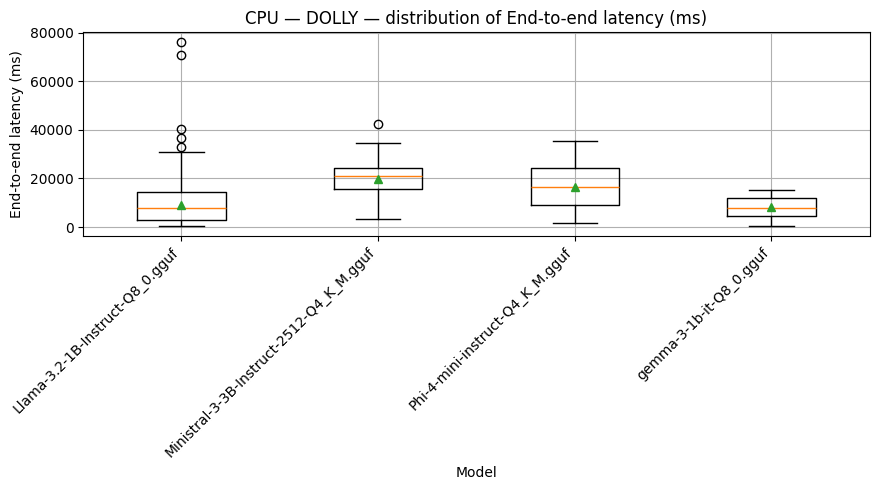

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


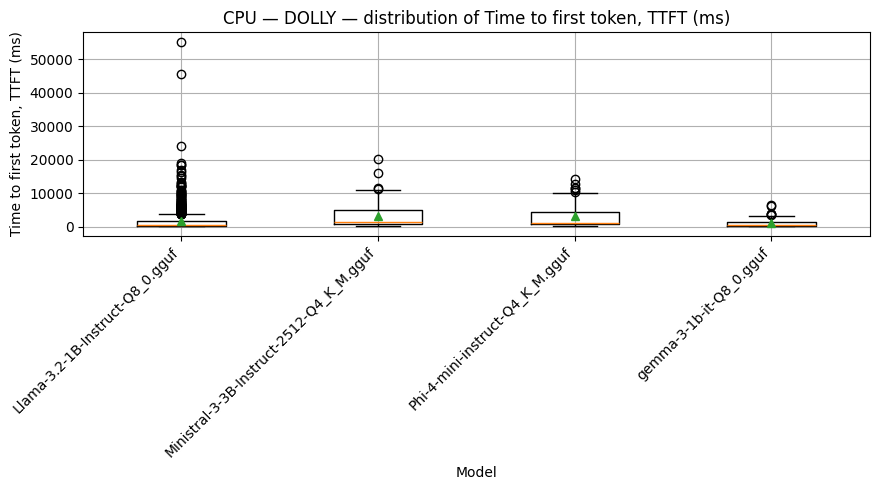

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


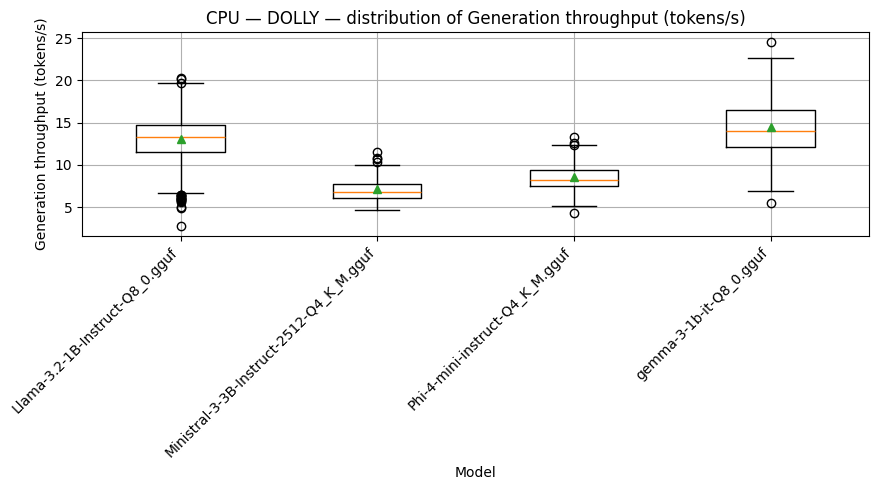

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


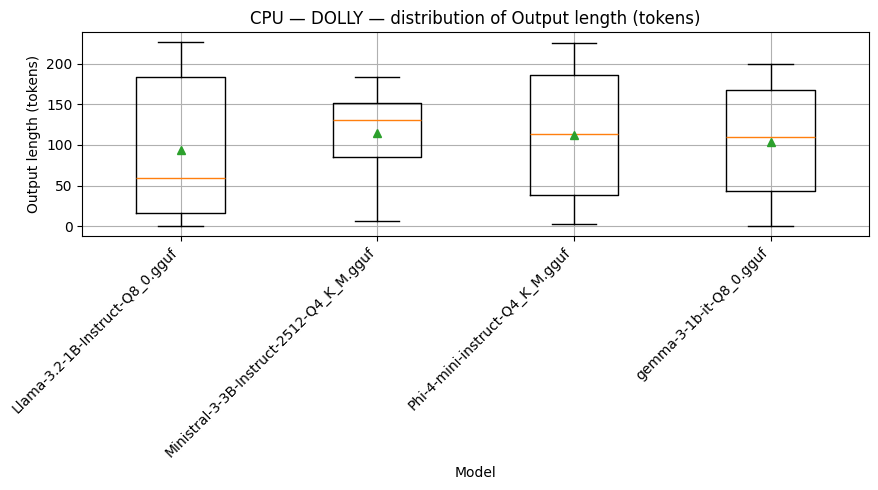

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


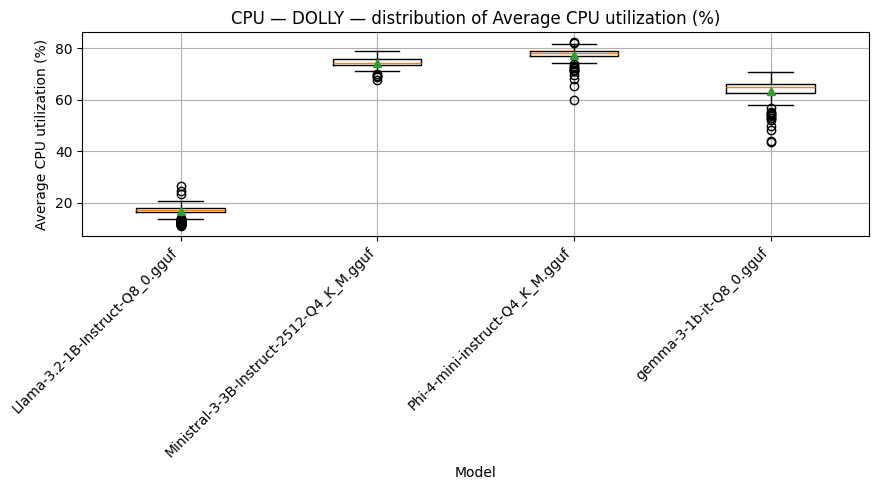

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


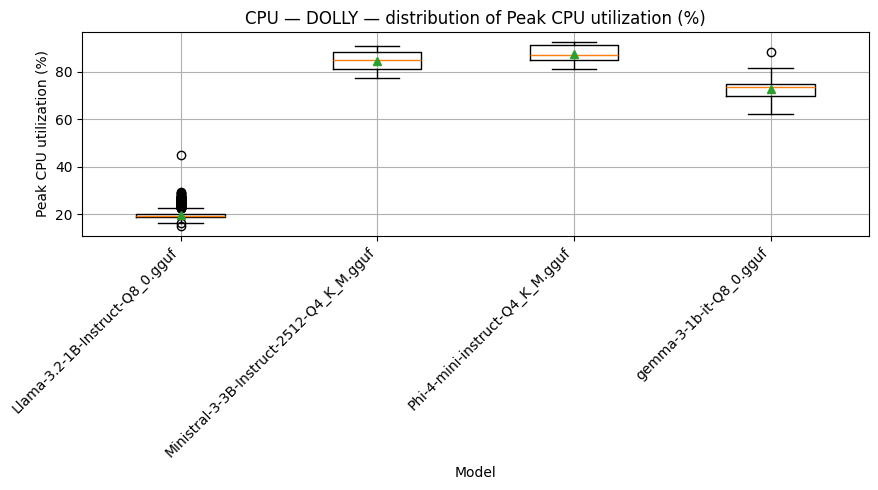

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


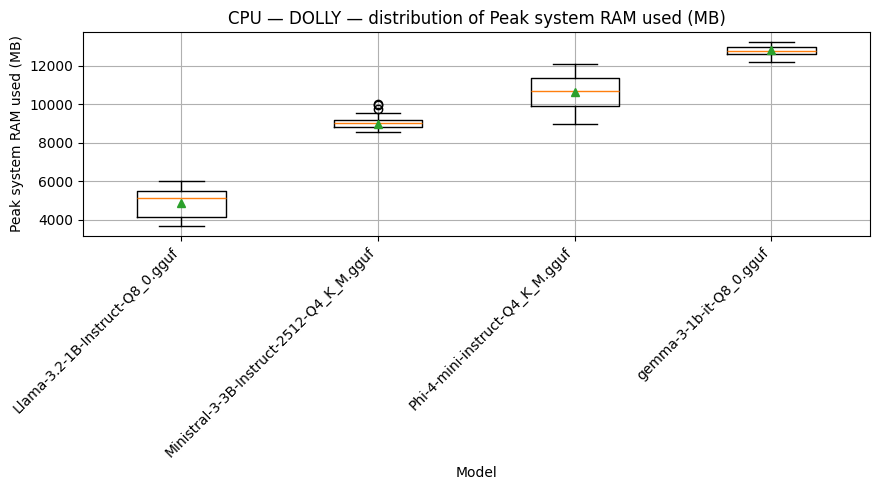

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


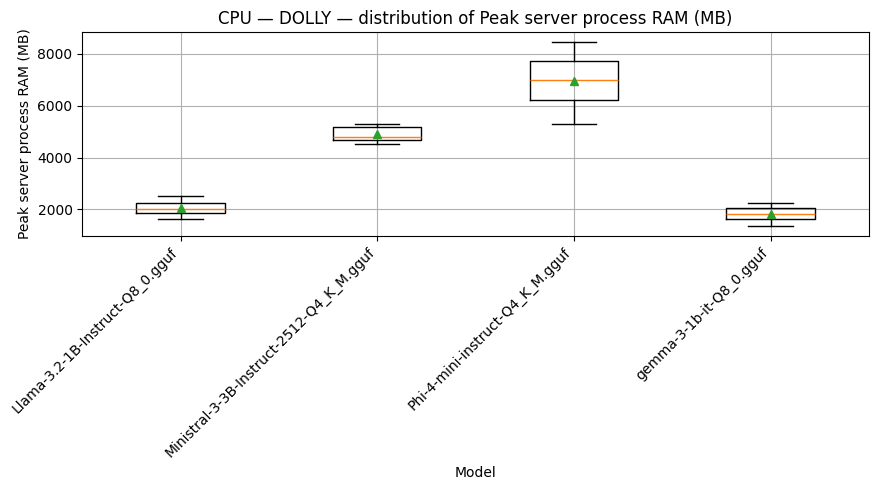

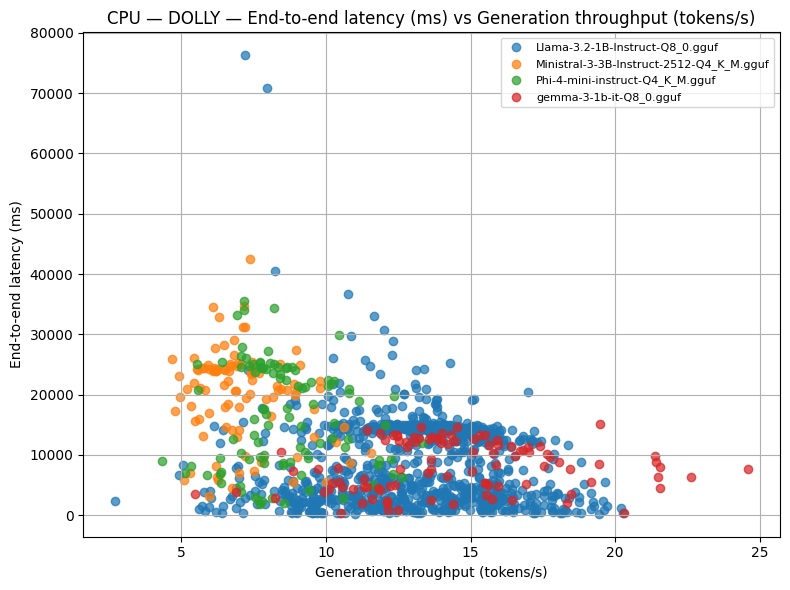

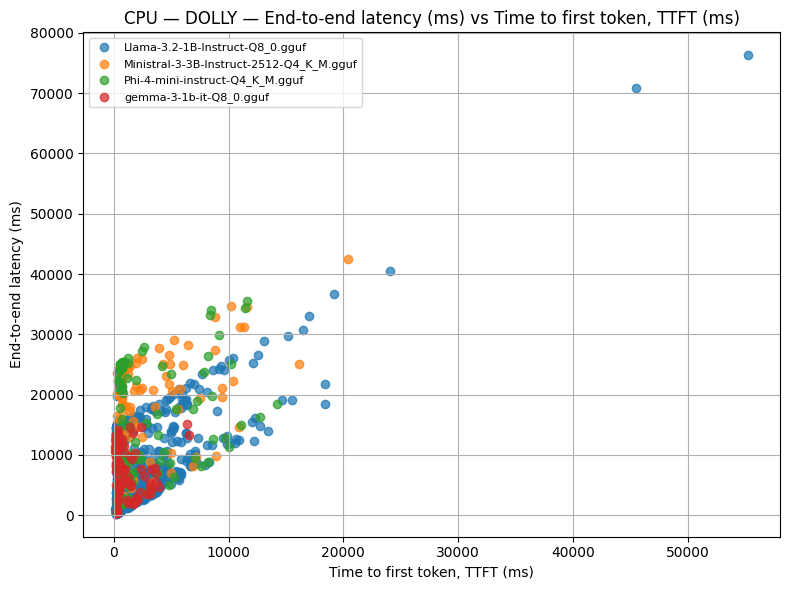

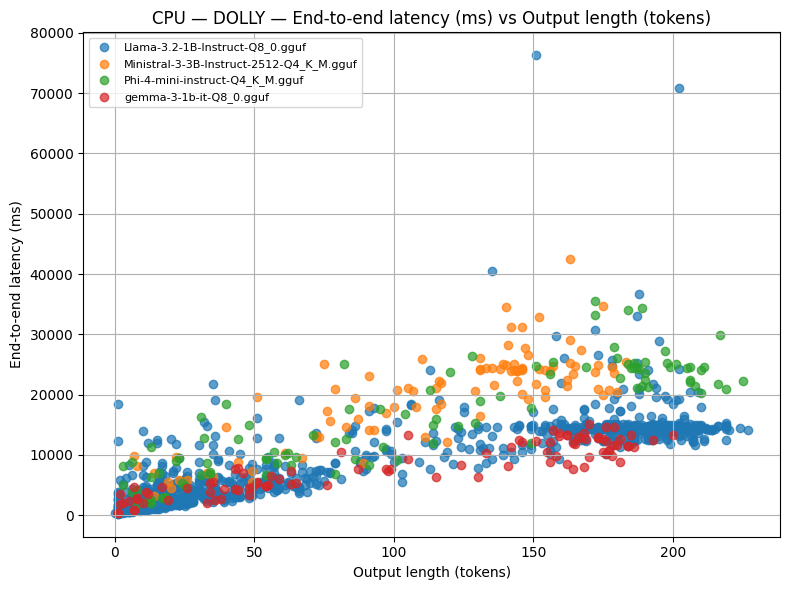

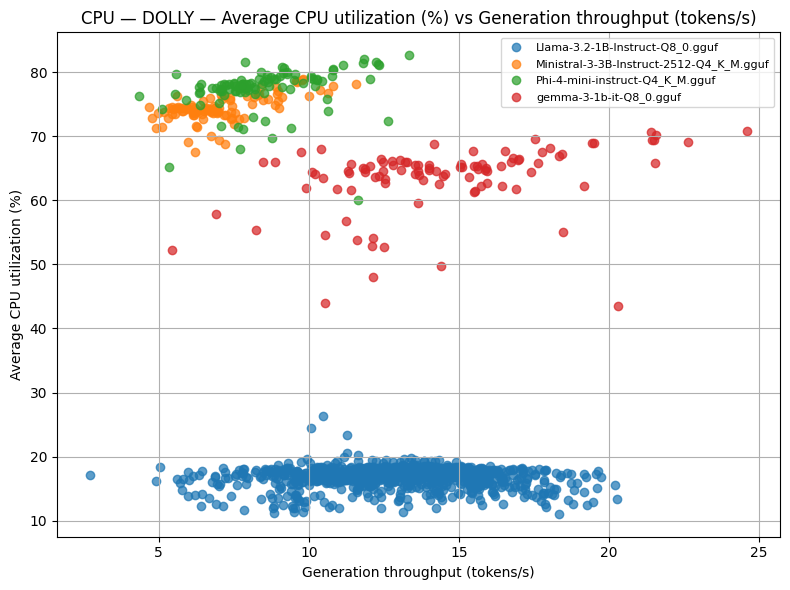

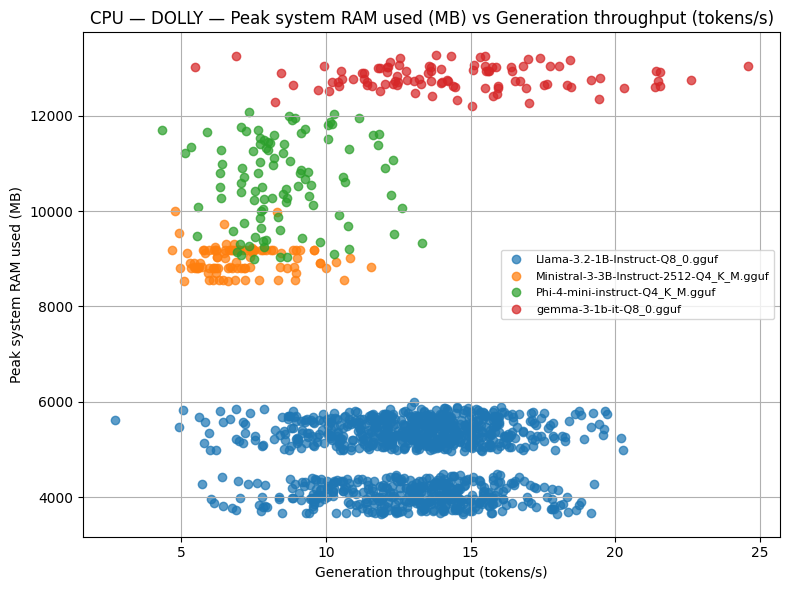

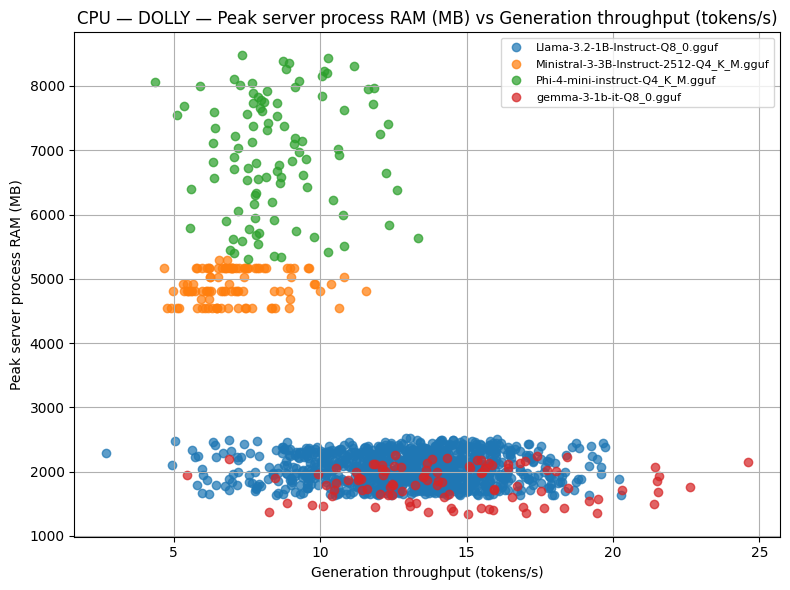


=== CPU / GSM8K ===


,model,accuracy,latency_ms,ttft_ms,tokens_per_sec,sustained_tokens_per_sec,samples_per_sec,cpu_percent_avg,cpu_percent_peak,ram_used_mb_peak,process_ram_mb_peak,accuracy_per_second
2,Phi-4-mini-instruct-Q4_K_M.gguf,0.64,17275.4491,2356.9669,8.0599,6.7864,0.0579,80.7400,94.4,11424.79,8123.45,0.037047
1,Ministral-3-3B-Instruct-2512-Q4_K_M.gguf,0.58,21516.9500,2462.0228,6.1389,5.2927,0.0464,73.2829,98.8,12899.34,4432.80,0.026955
3,gemma-3-1b-it-Q8_0.gguf,0.47,11588.0723,765.0664,13.2622,12.0060,0.0860,65.2058,81.6,13044.35,2207.14,0.040559
0,Llama-3.2-1B-Instruct-Q8_0.gguf,0.14,3220.7195,933.7012,12.4660,8.5791,0.3068,15.9904,30.4,5254.59,1906.89,0.043469


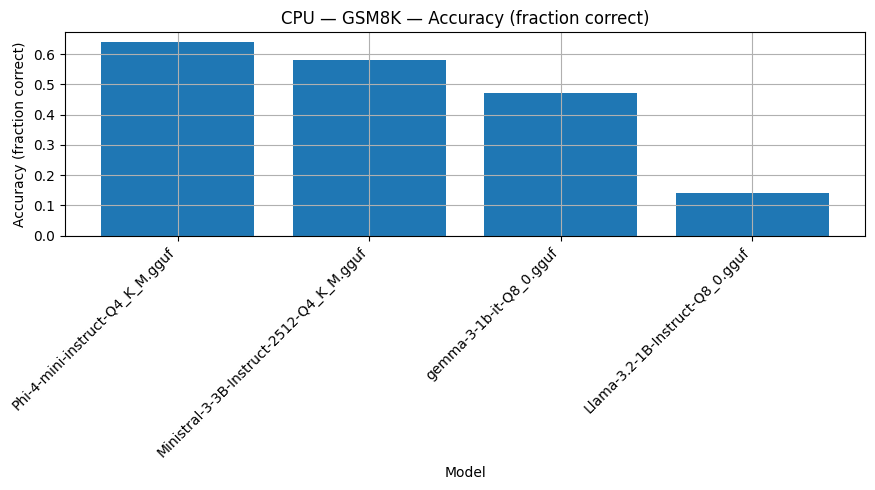

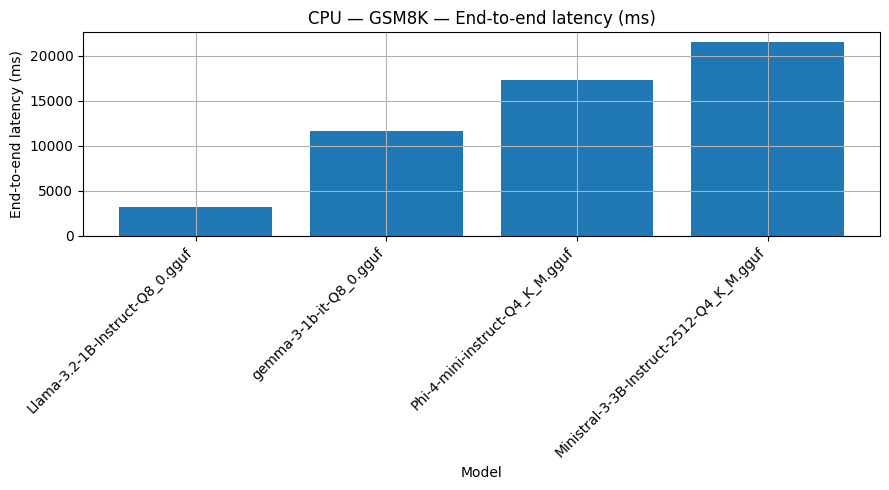

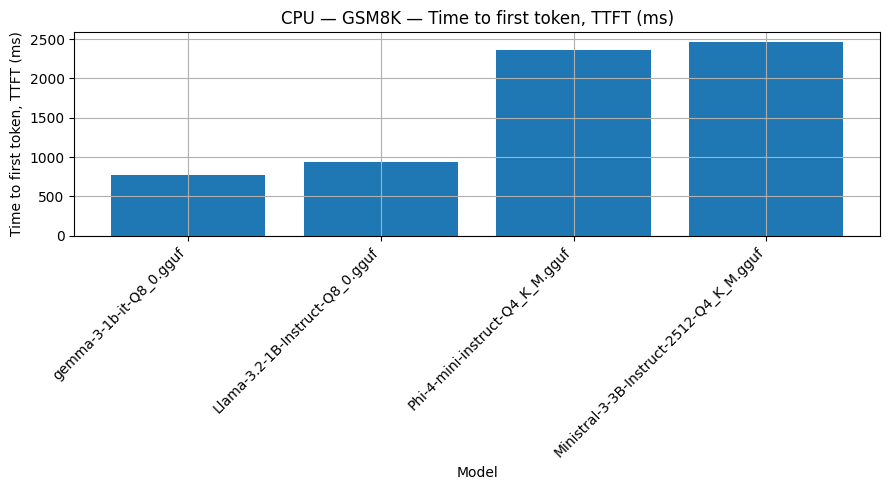

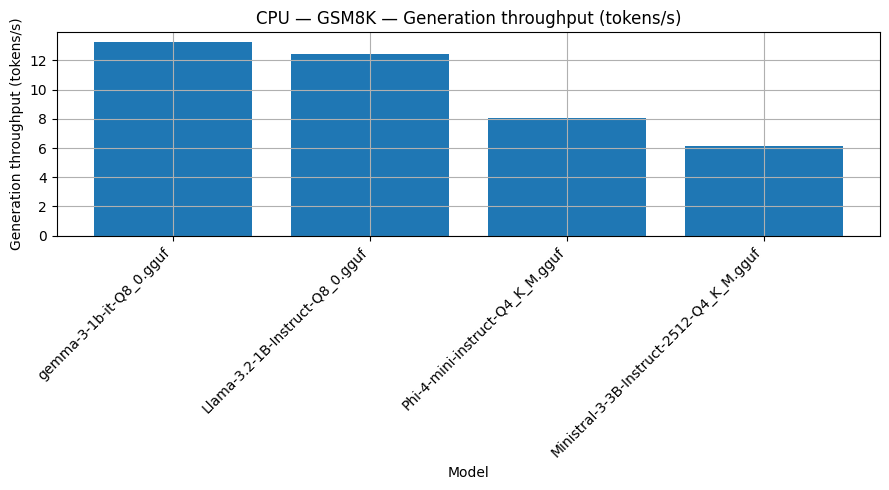

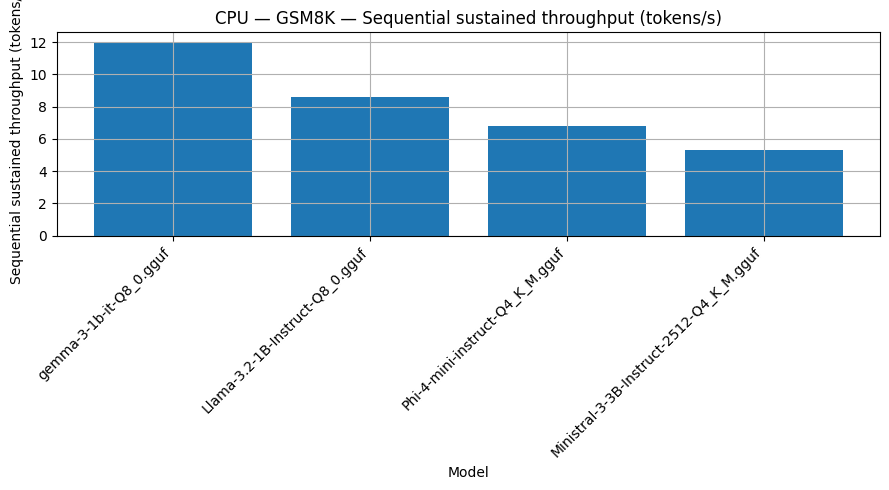

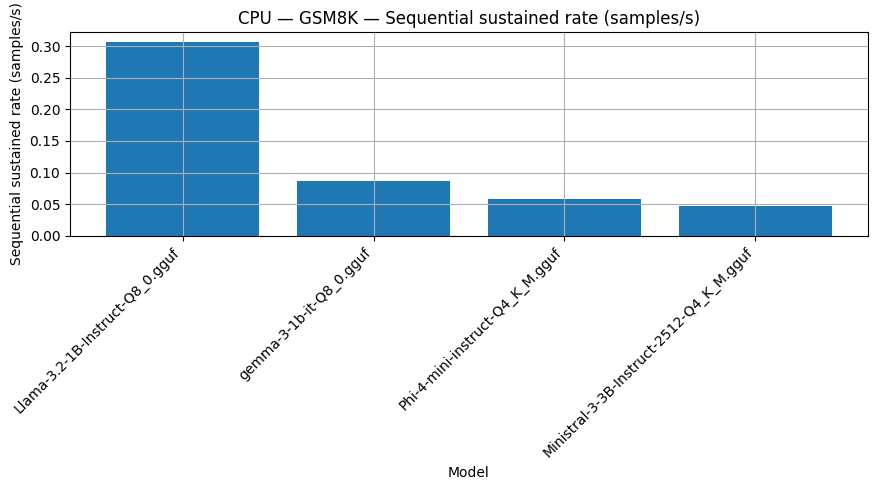

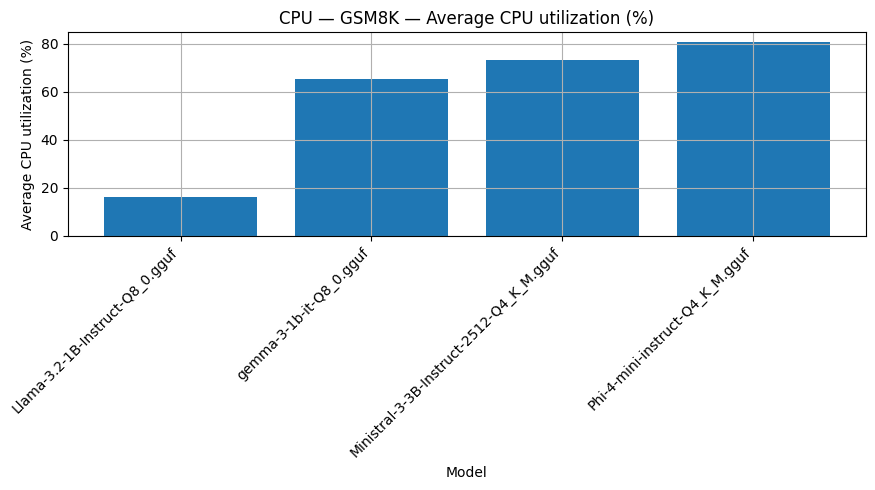

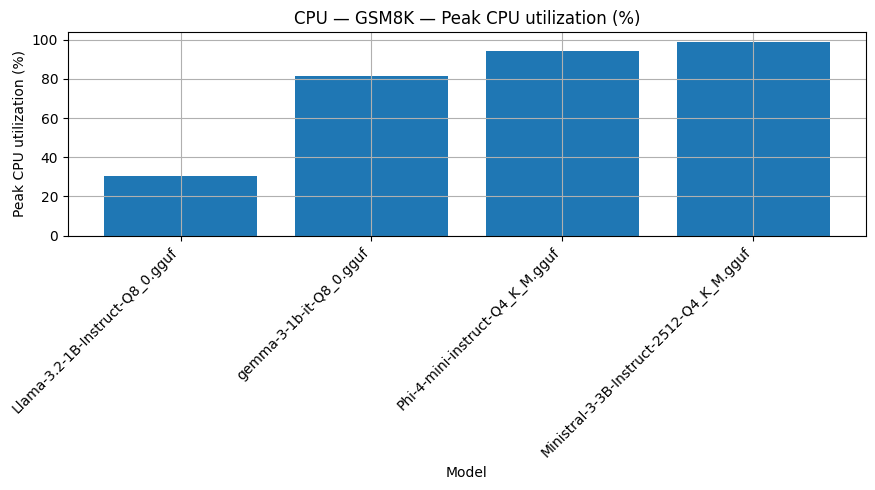

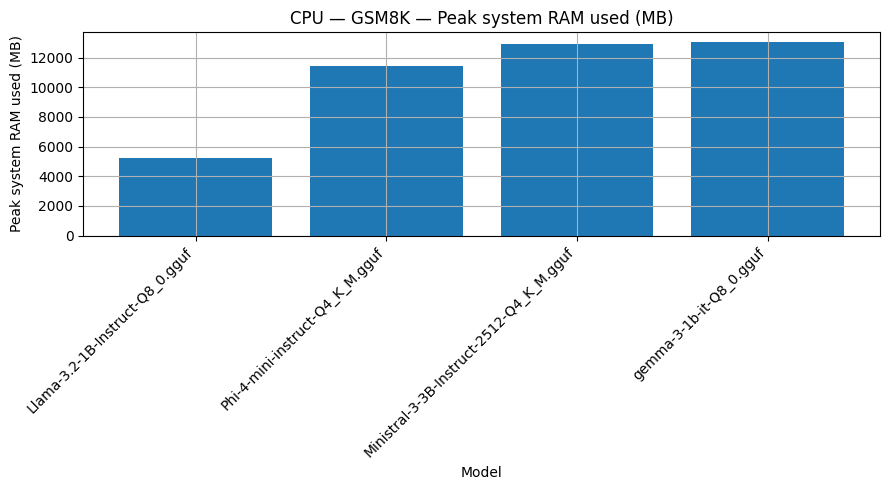

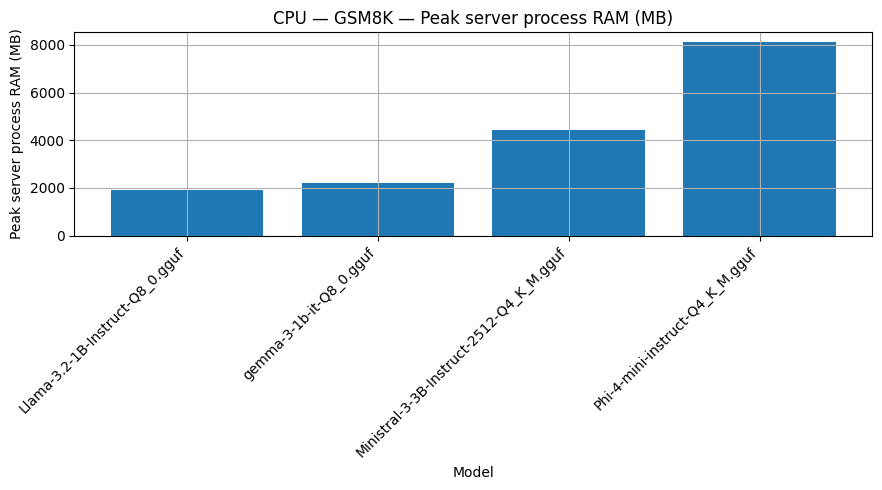

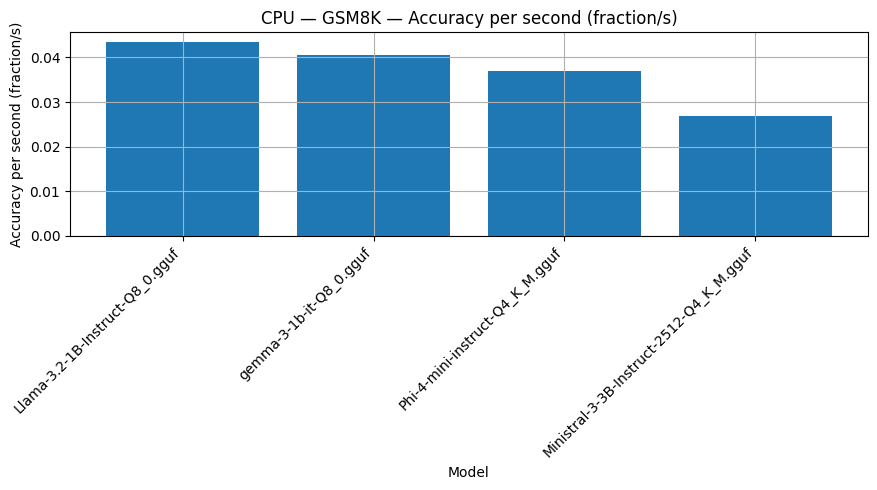

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


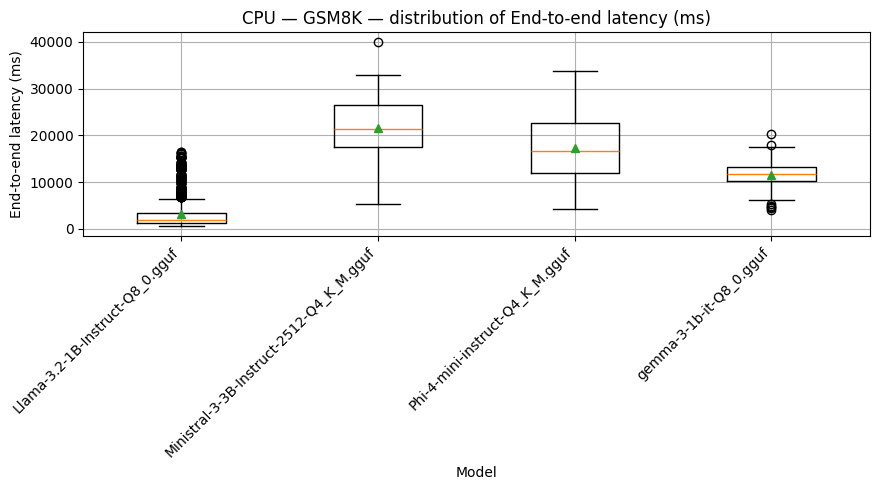

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


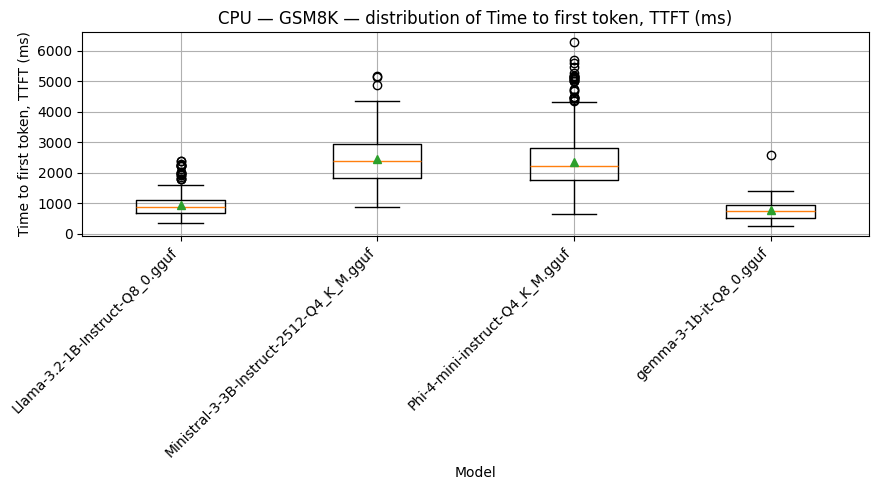

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


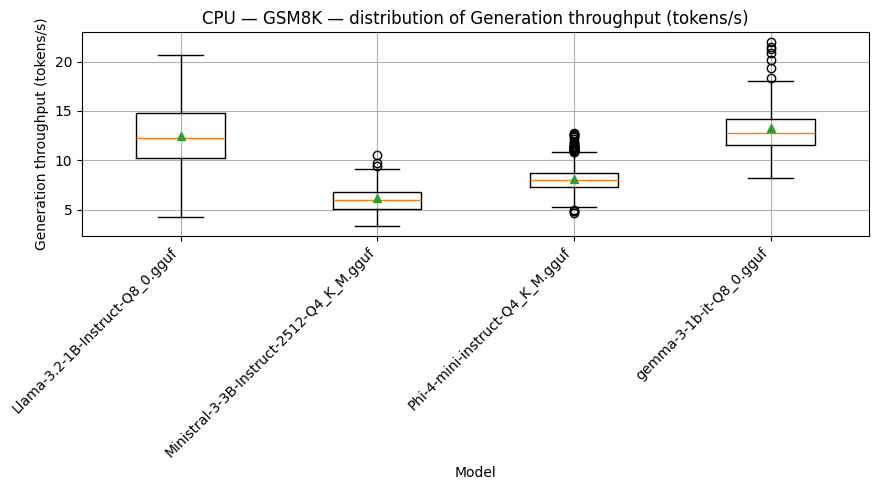

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


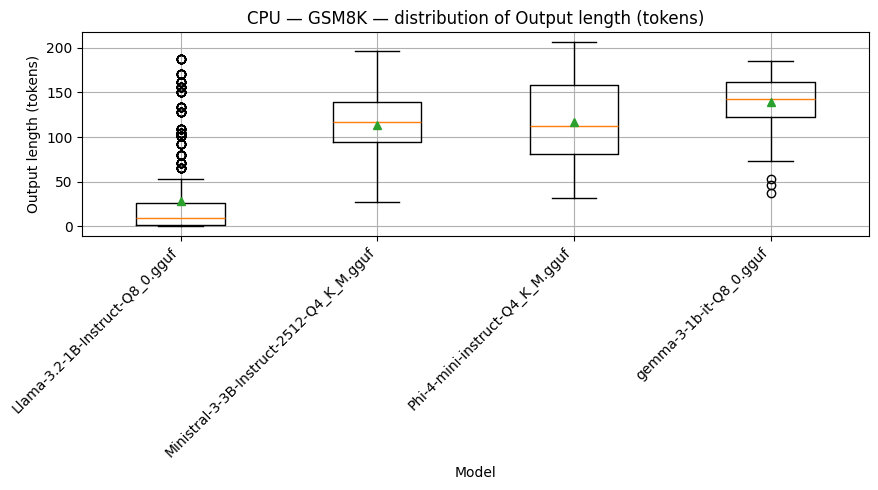

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


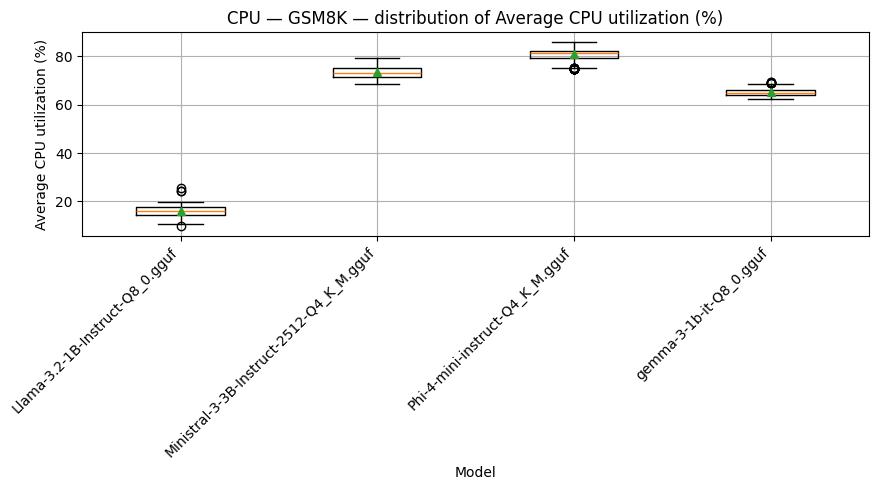

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


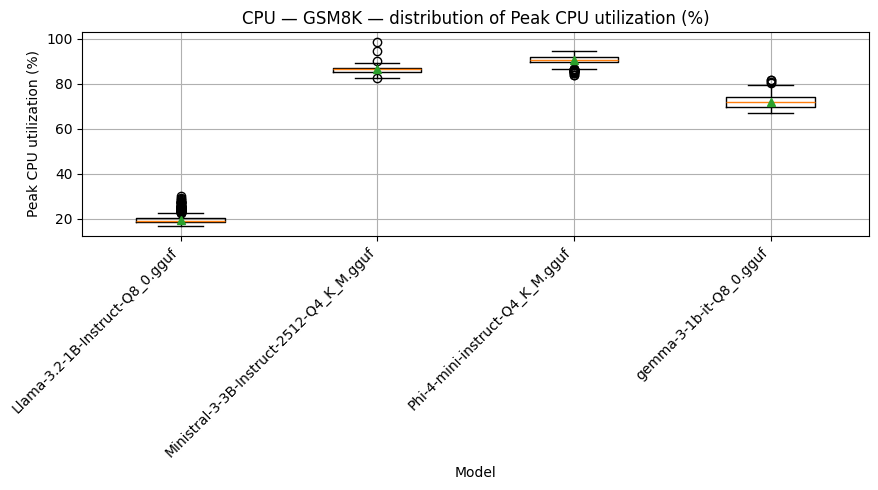

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


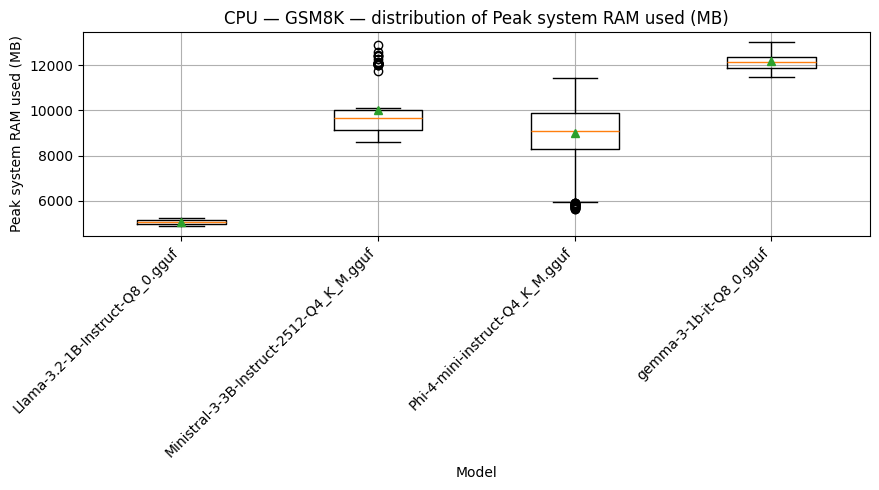

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


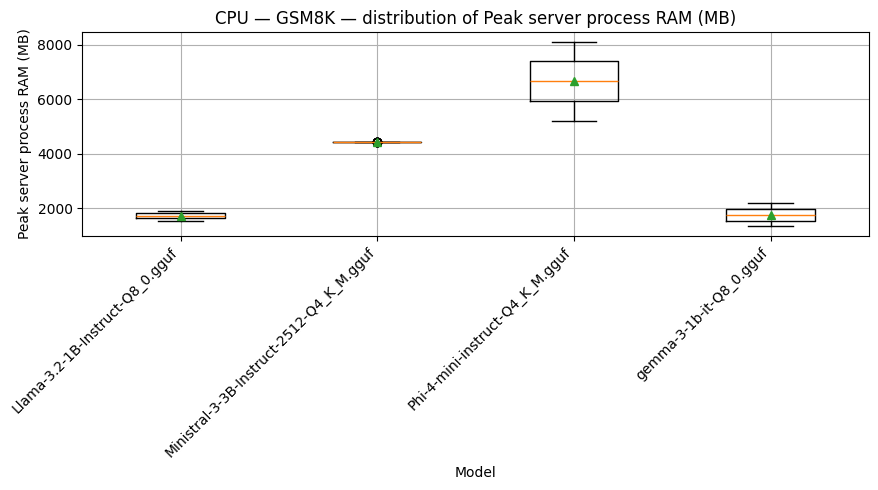

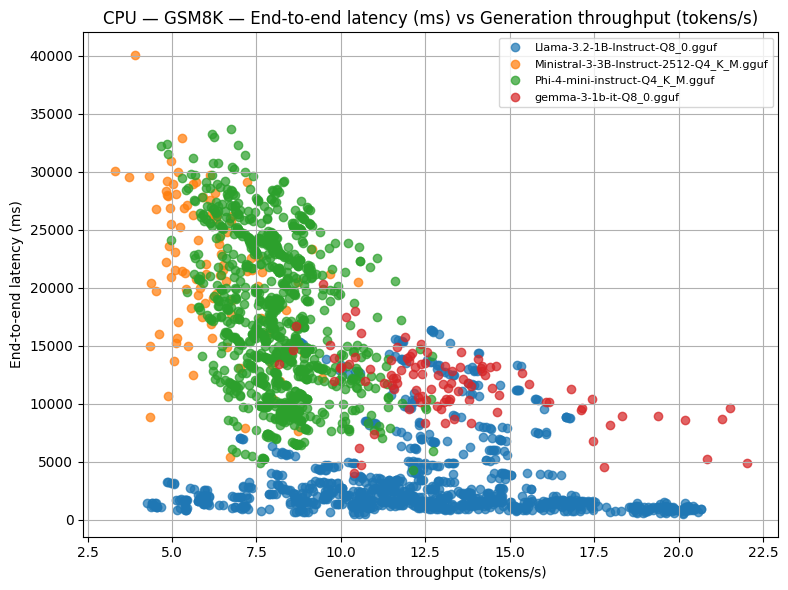

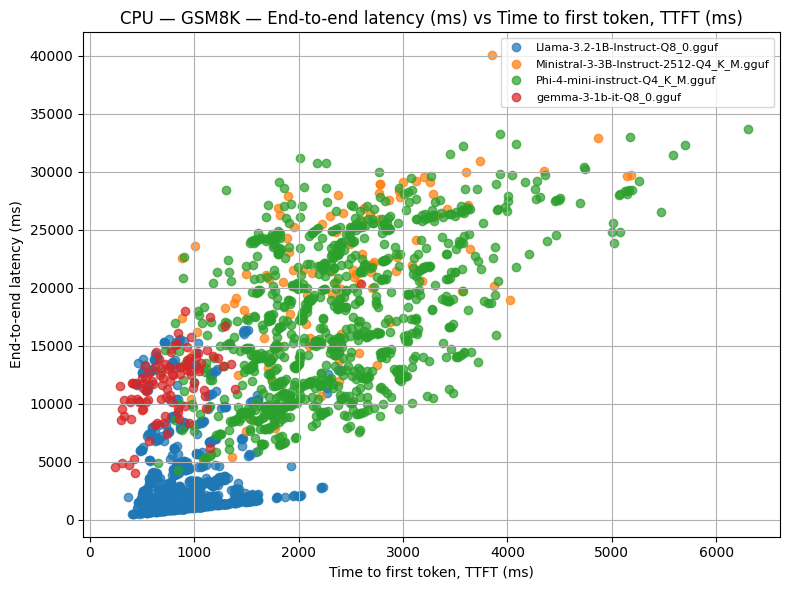

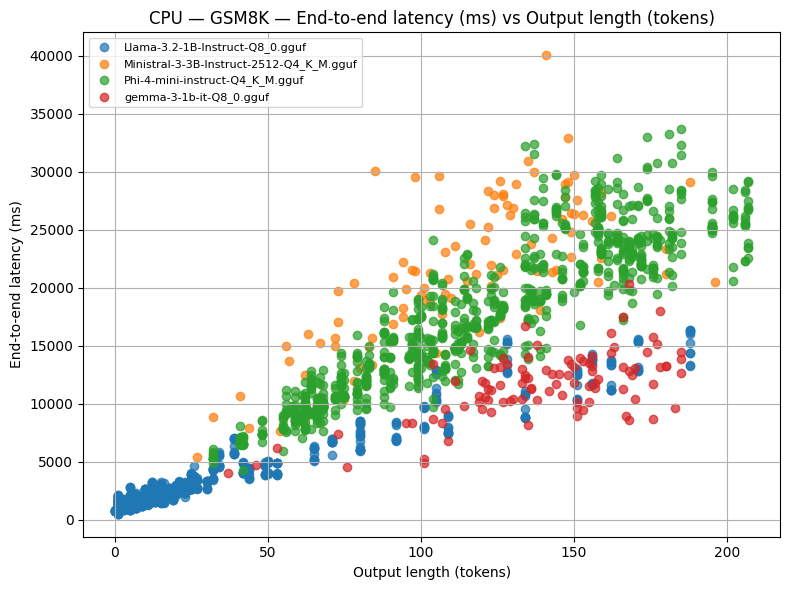

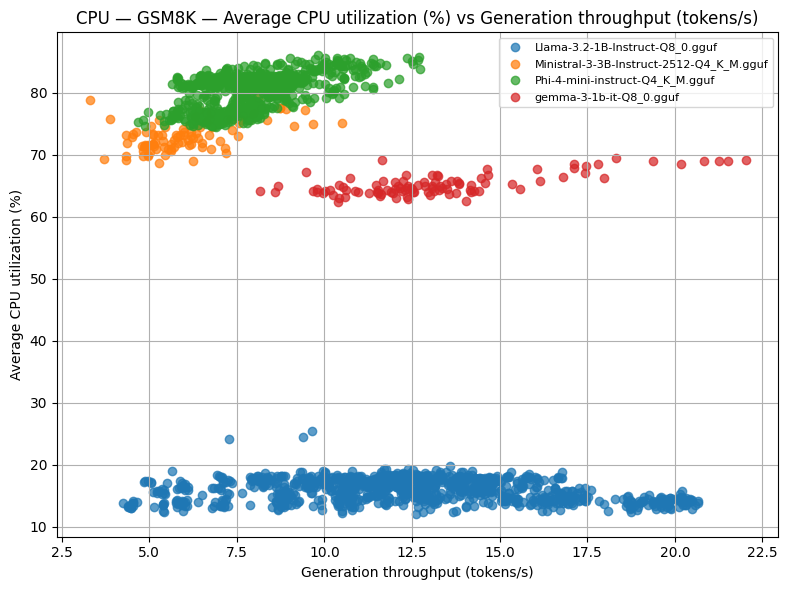

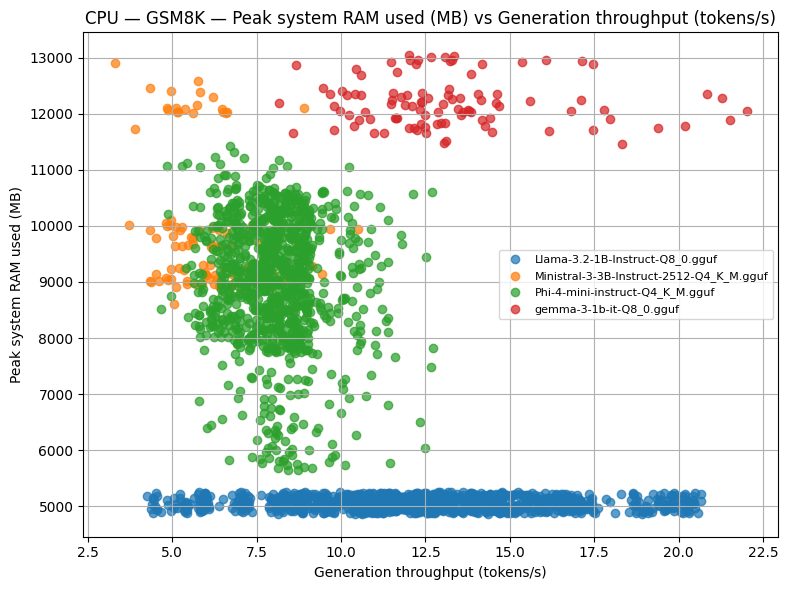

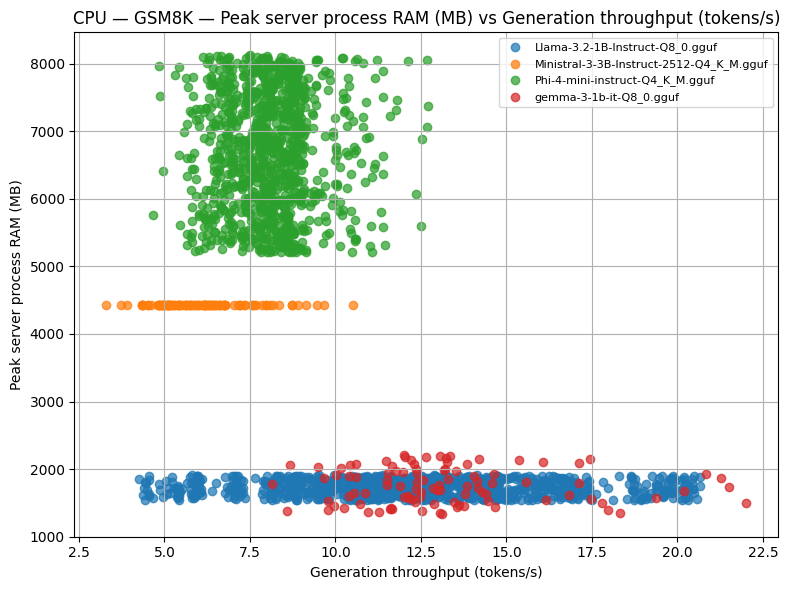

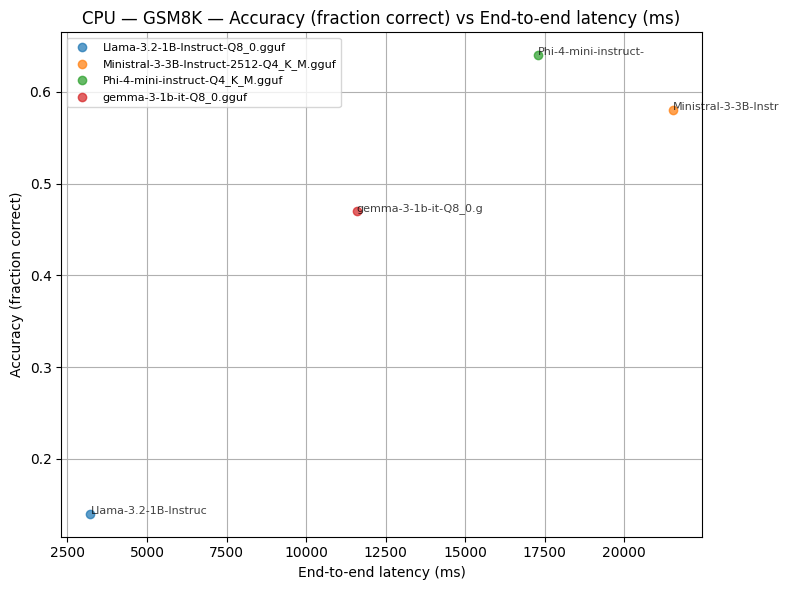

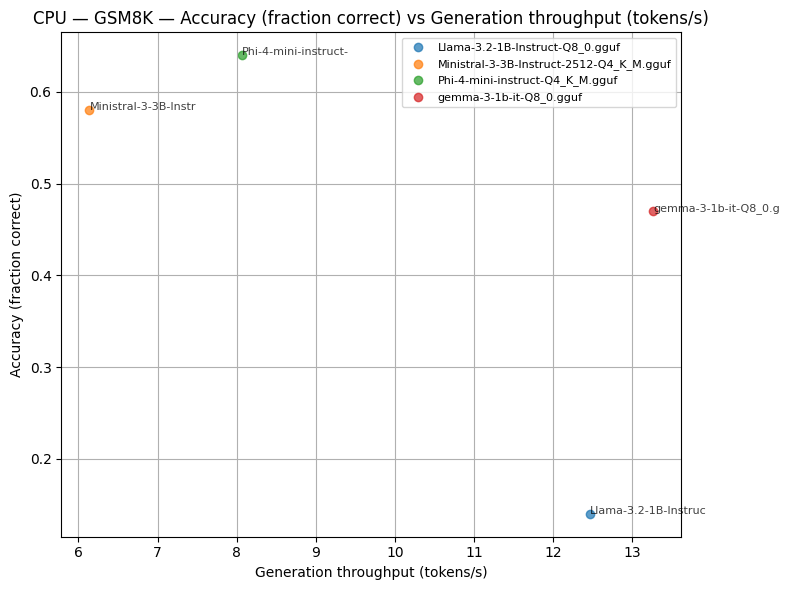

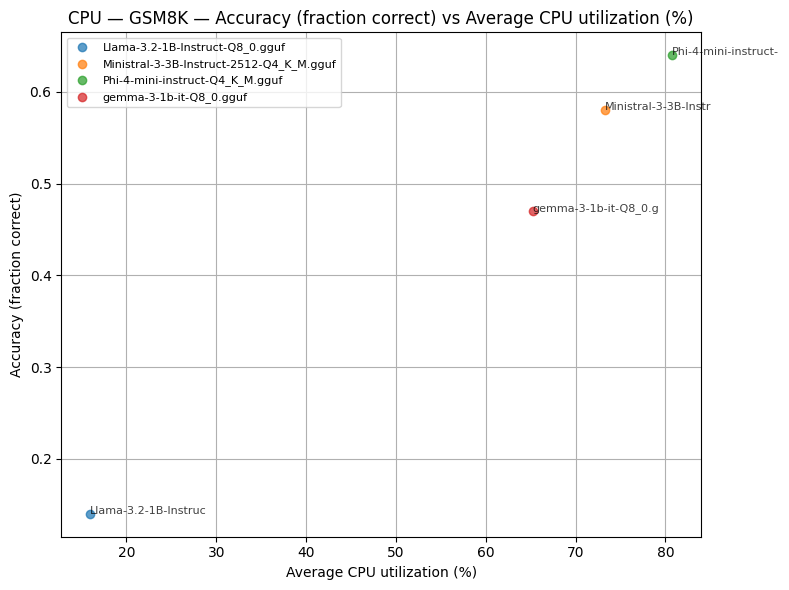

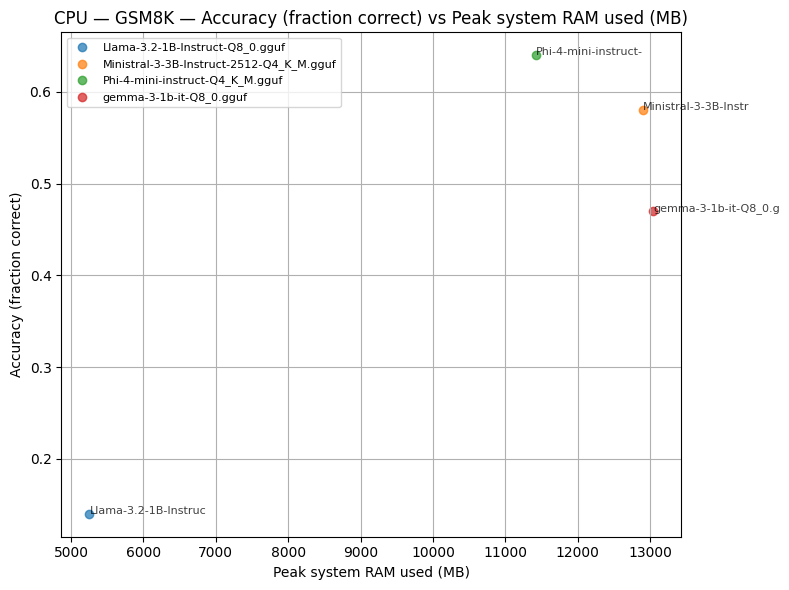

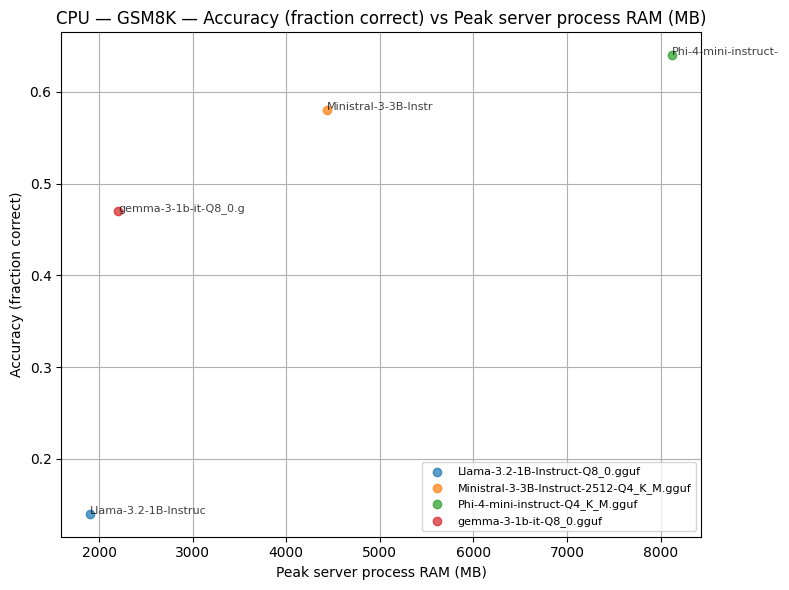

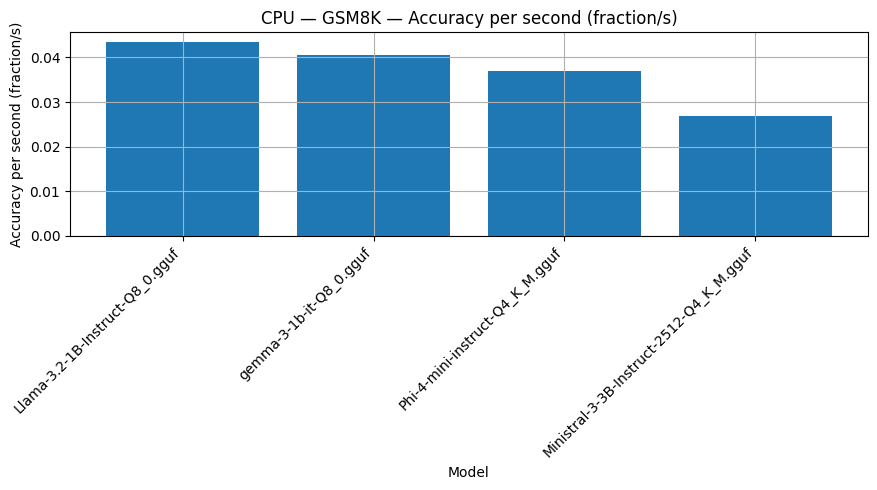


=== CPU / HELLASWAG ===


,model,accuracy,latency_ms,ttft_ms,tokens_per_sec,sustained_tokens_per_sec,samples_per_sec,cpu_percent_avg,cpu_percent_peak,ram_used_mb_peak,process_ram_mb_peak,accuracy_per_second
2,Phi-4-mini-instruct-Q4_K_M.gguf,0.51,5729.9374,5433.3107,9.7872,0.5159,0.1734,57.7476,96.2,11392.52,7626.34,0.089006
1,Ministral-3-3B-Instruct-2512-Q4_K_M.gguf,0.39,8621.1334,8495.9497,8.0530,0.1155,0.1155,12.4179,25.5,5276.07,4014.00,0.045238
0,Llama-3.2-1B-Instruct-Q8_0.gguf,0.29,2463.7357,2407.5919,18.0173,0.3997,0.3997,14.1960,30.2,5578.20,2251.58,0.117707
3,gemma-3-1b-it-Q8_0.gguf,0.29,1646.7807,1561.6347,12.4332,0.5961,0.5961,48.3830,79.0,12305.72,2375.02,0.176101


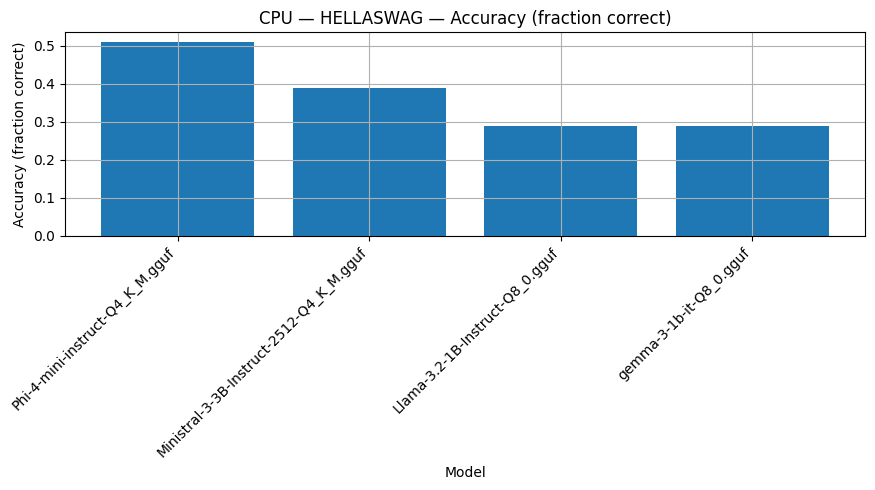

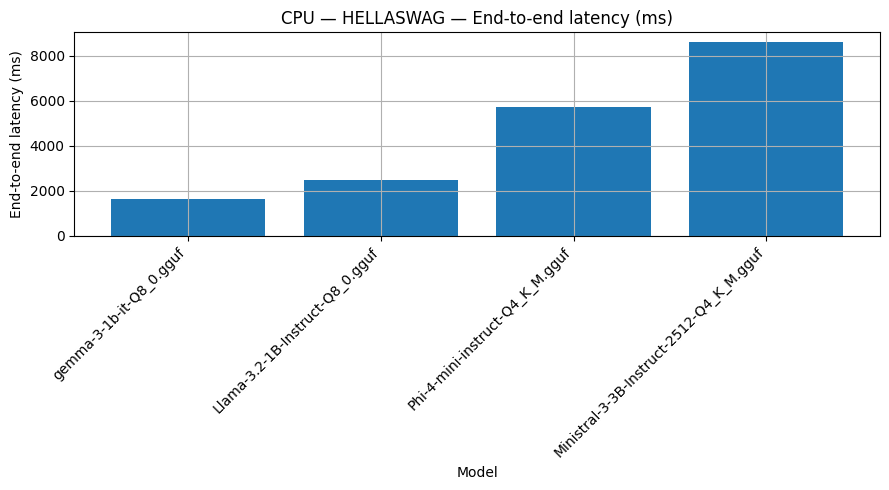

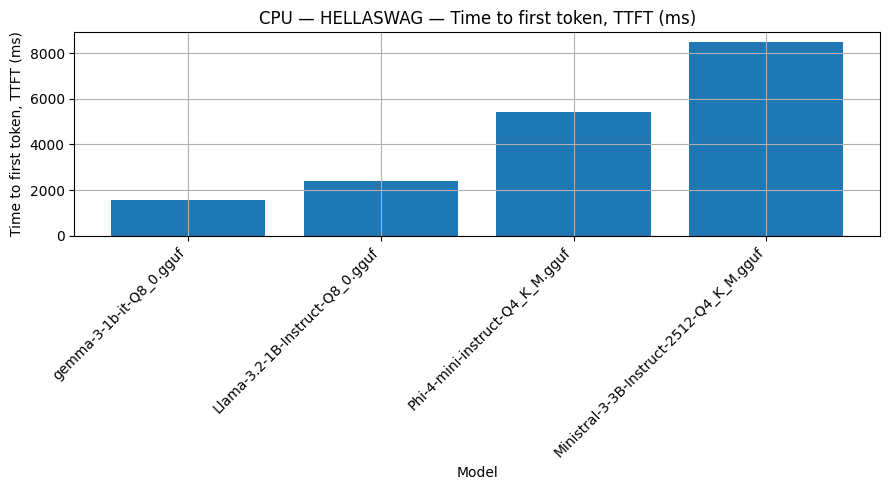

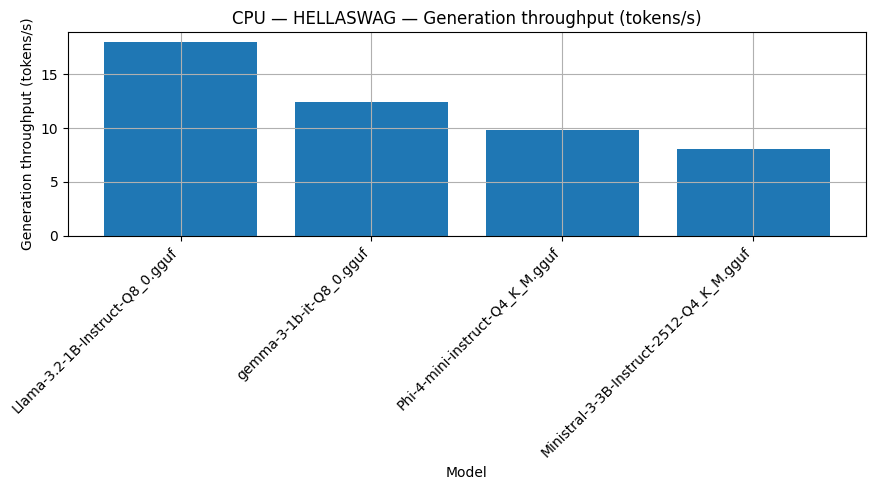

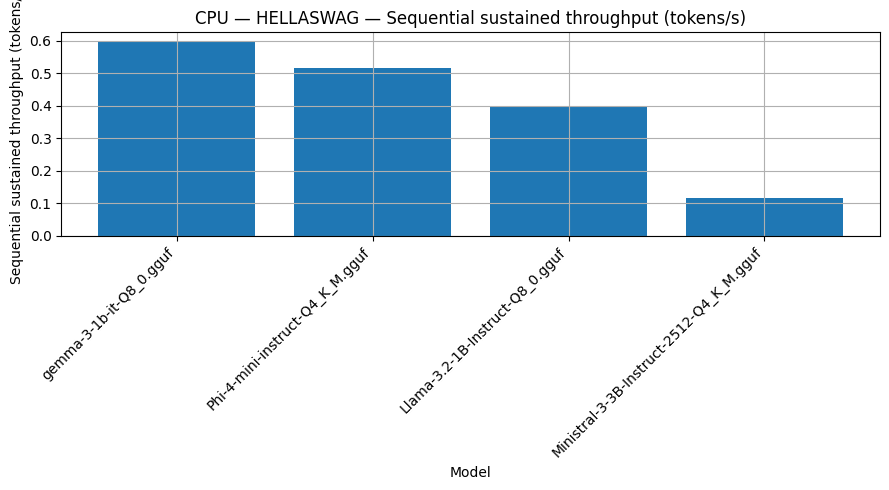

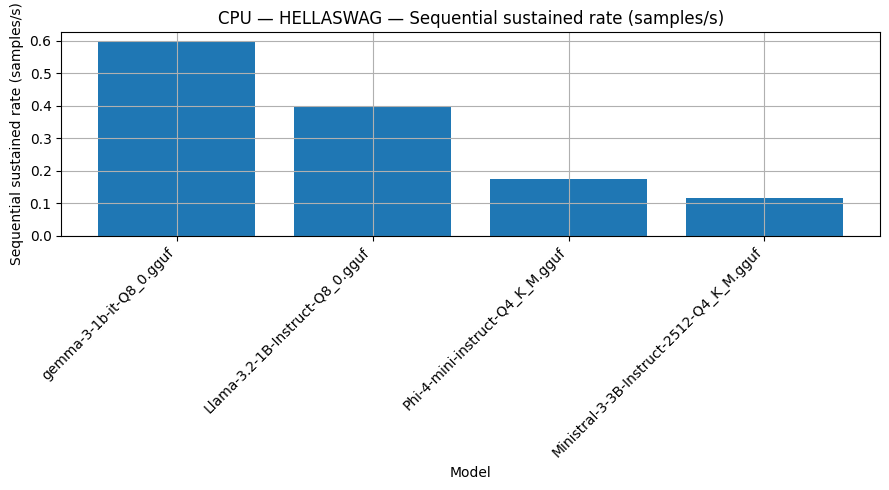

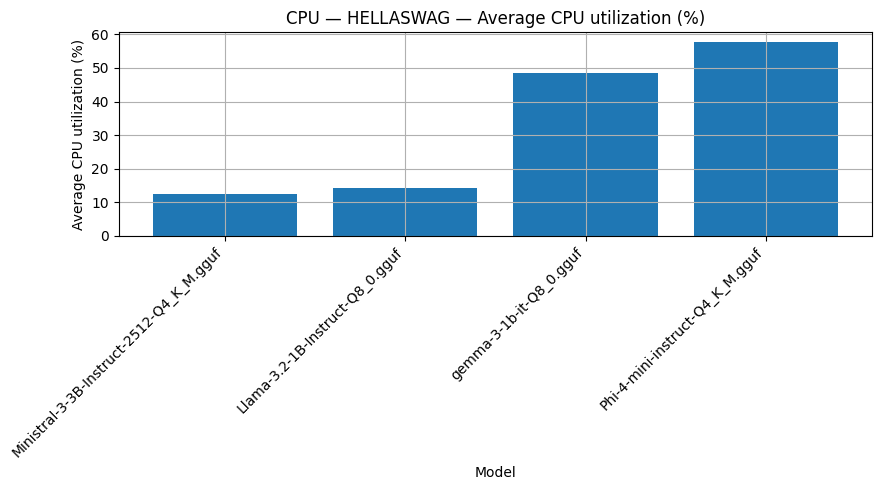

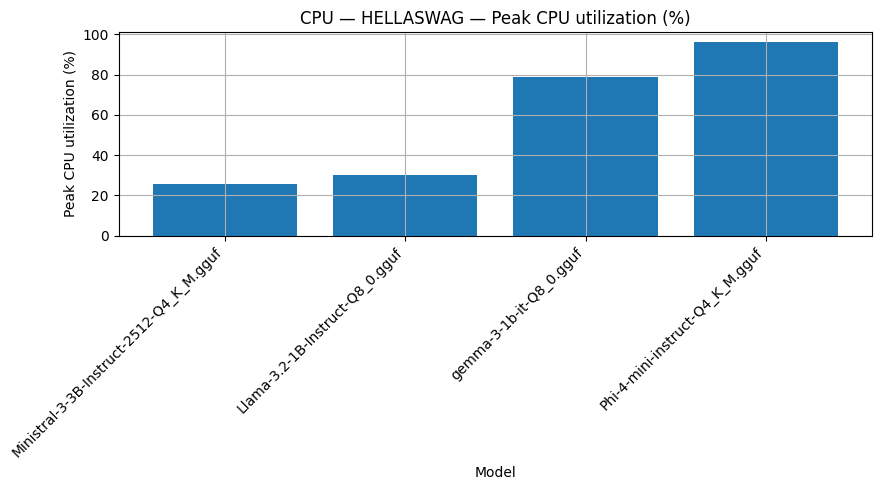

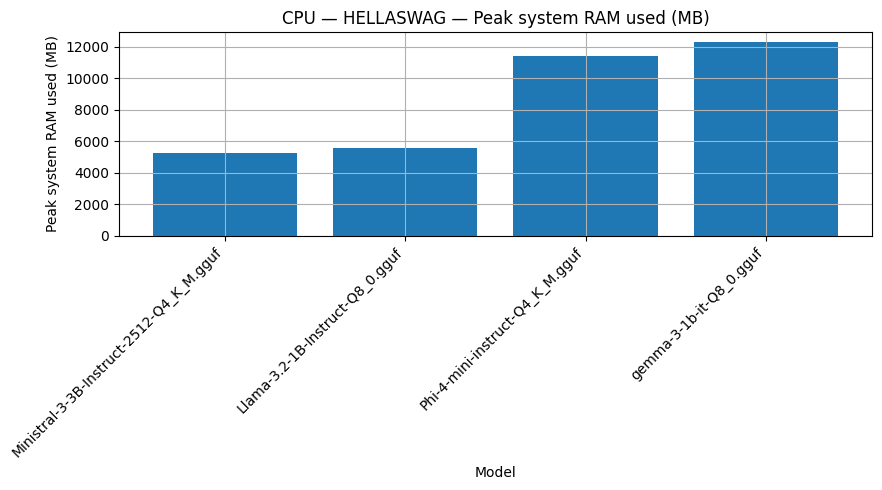

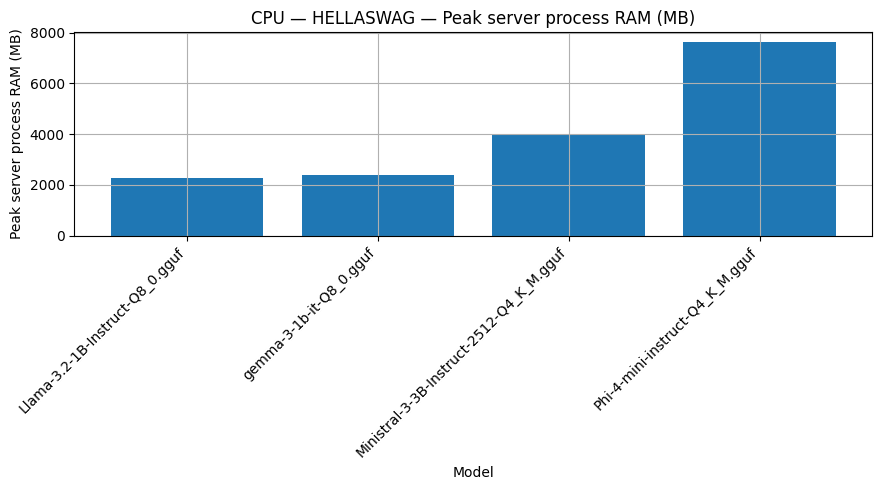

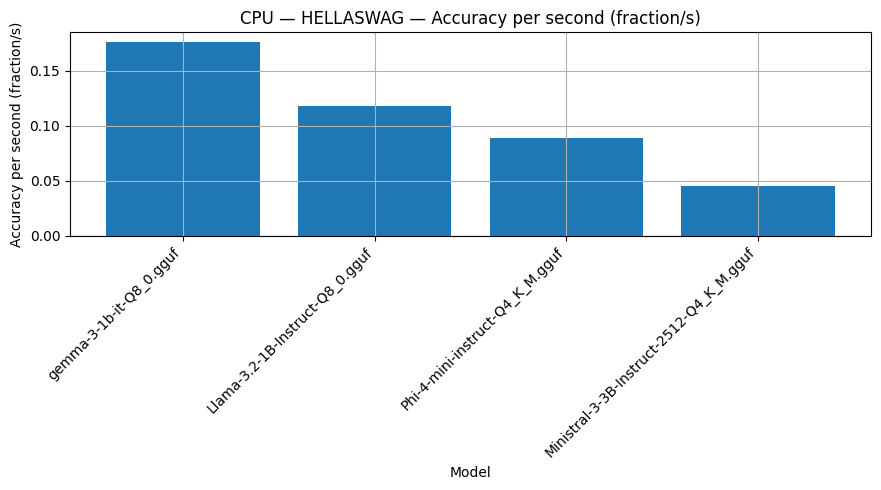

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


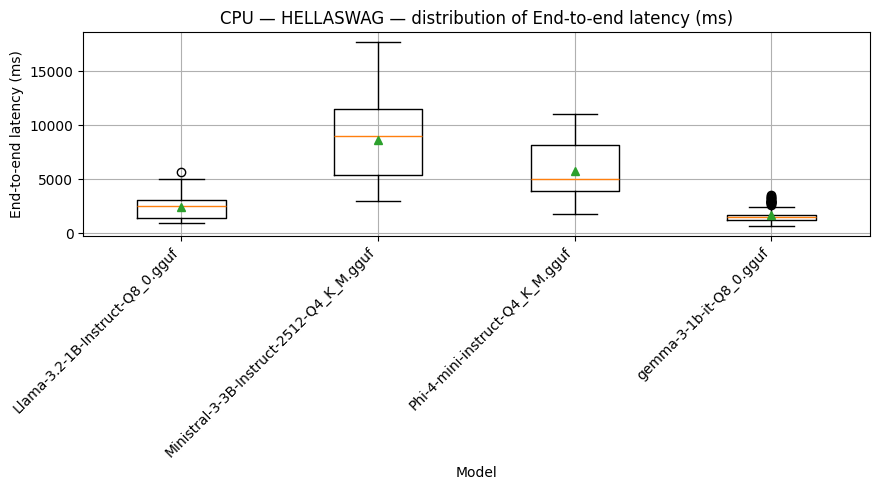

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


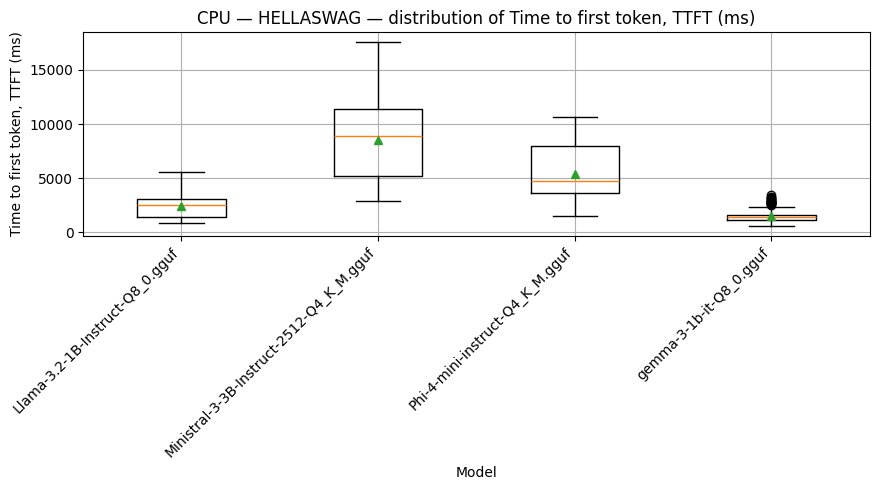

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


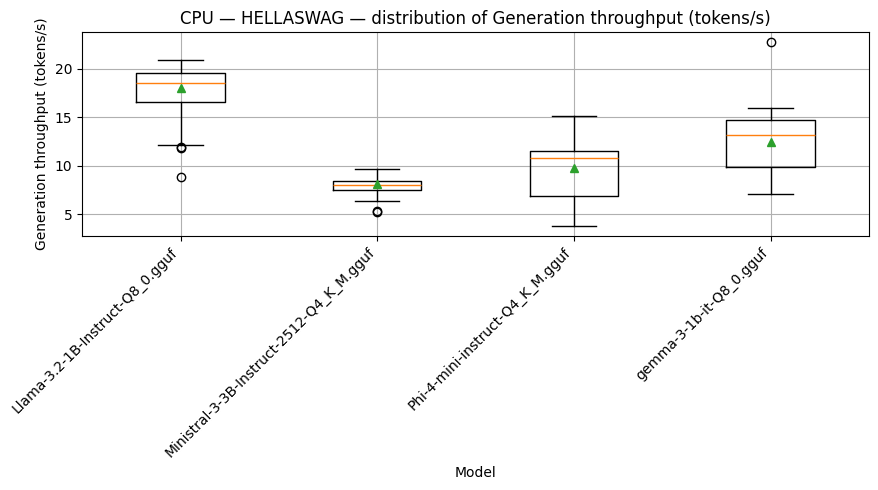

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


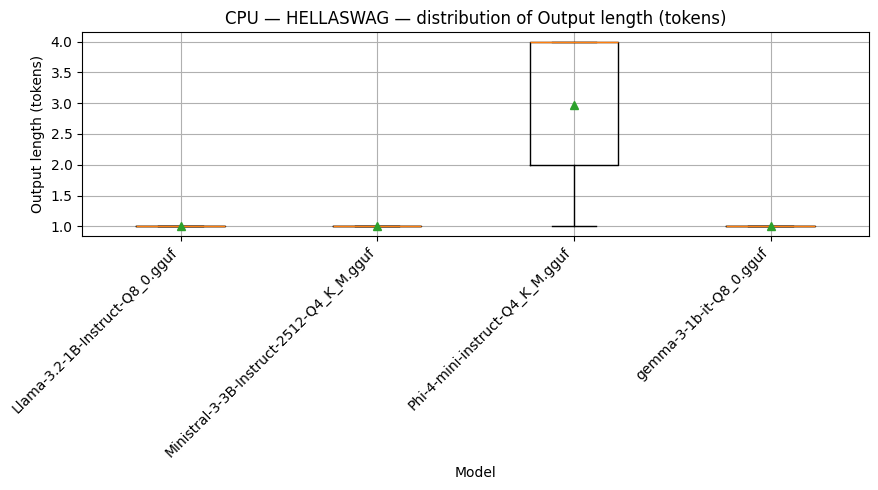

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


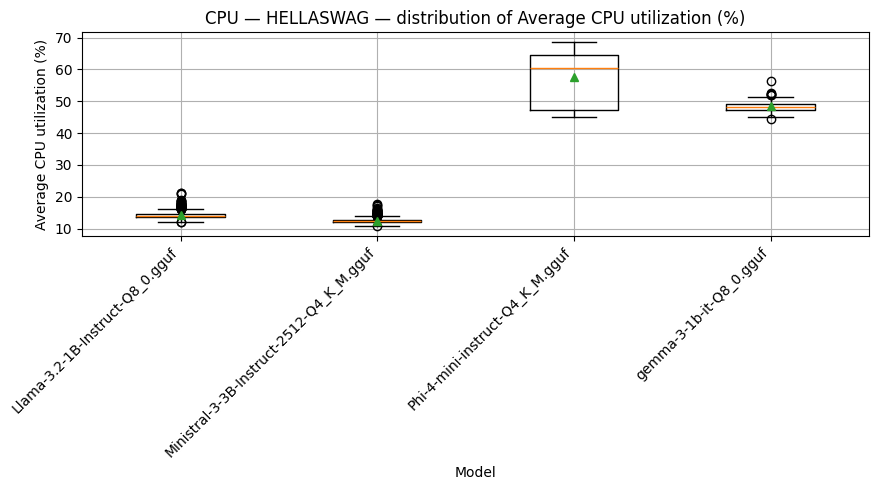

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


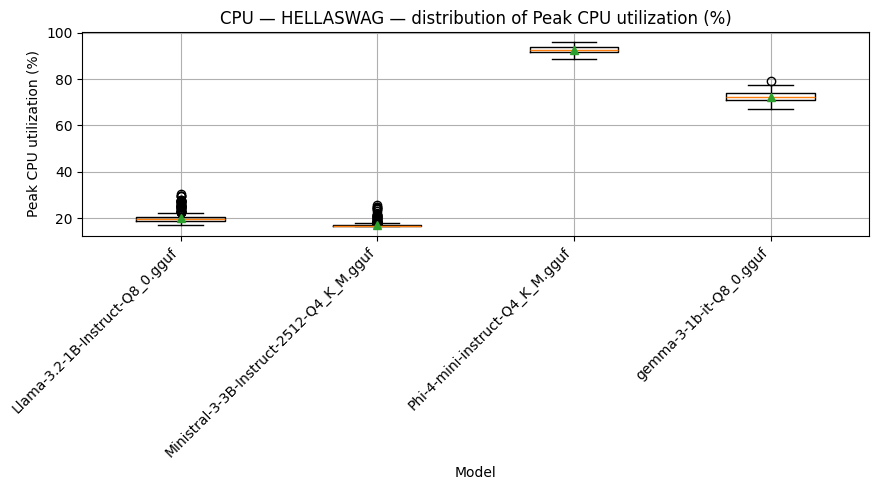

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


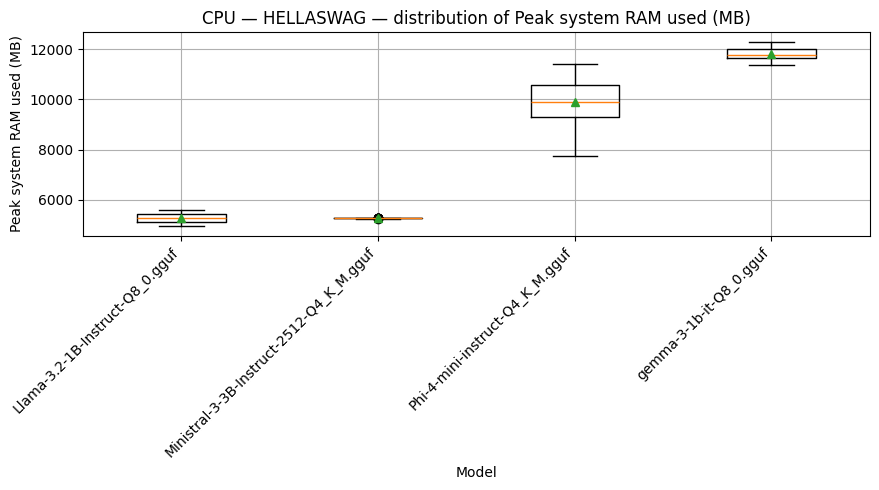

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


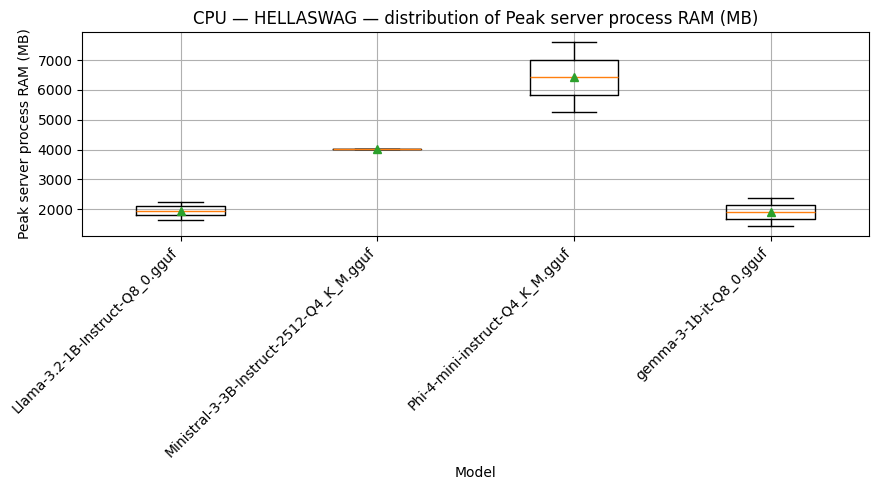

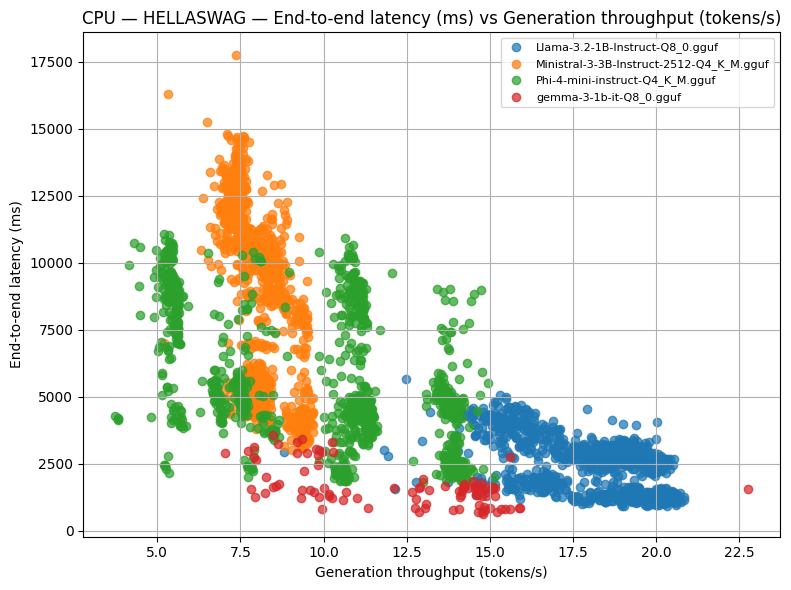

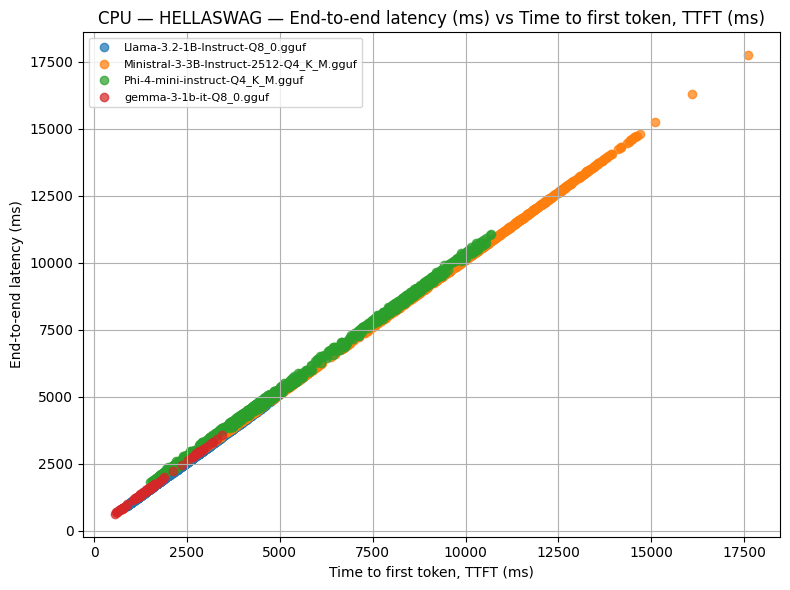

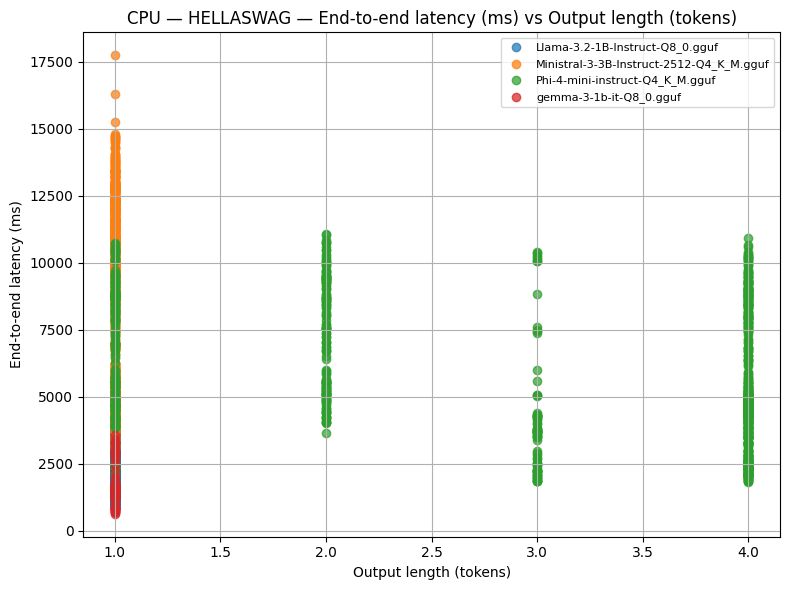

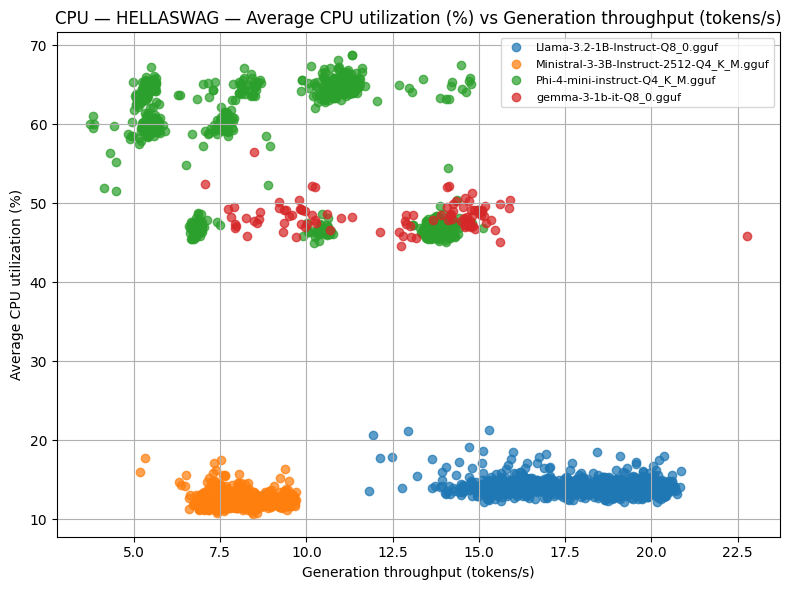

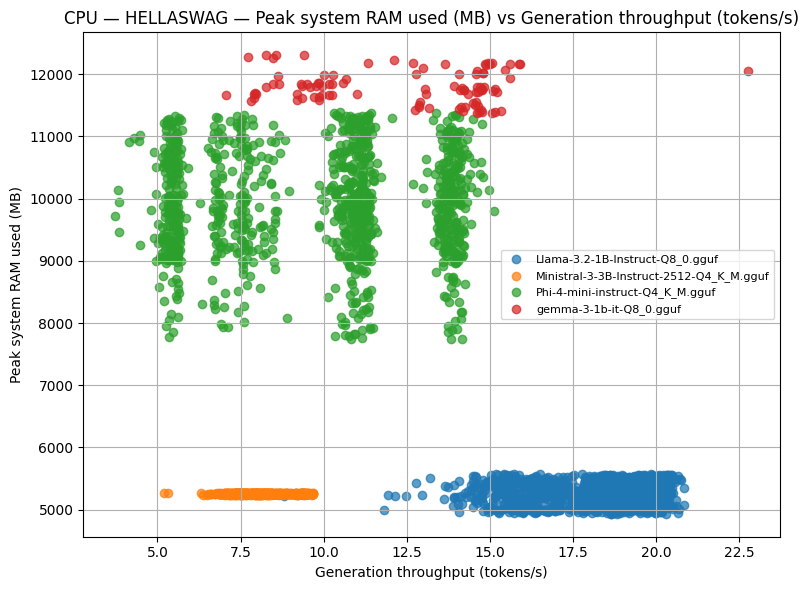

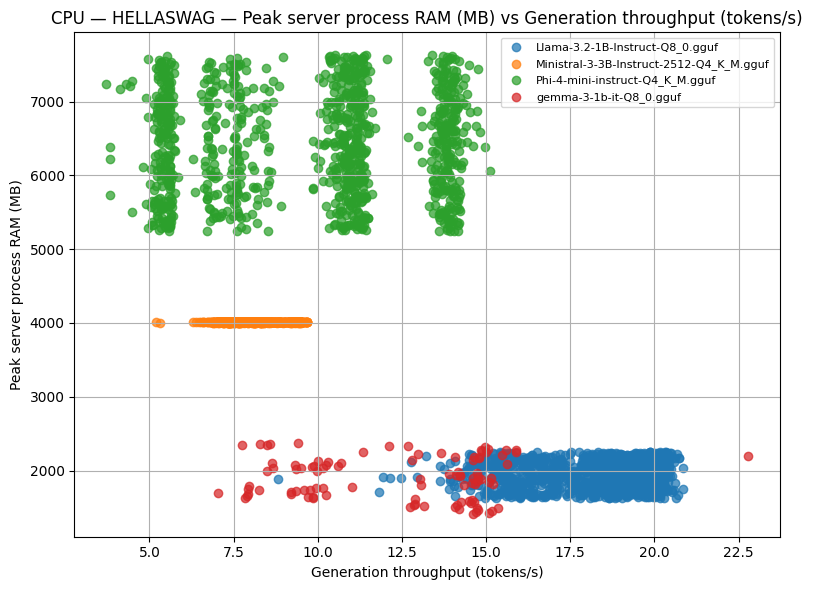

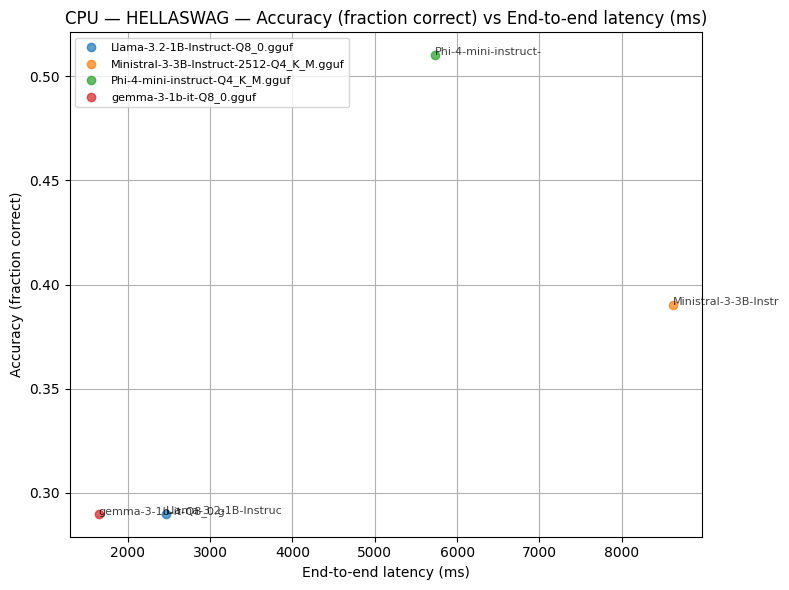

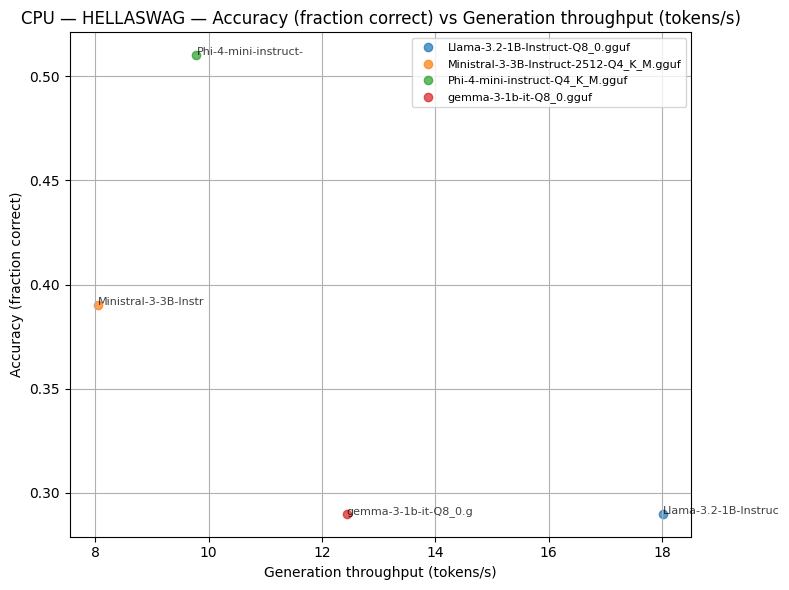

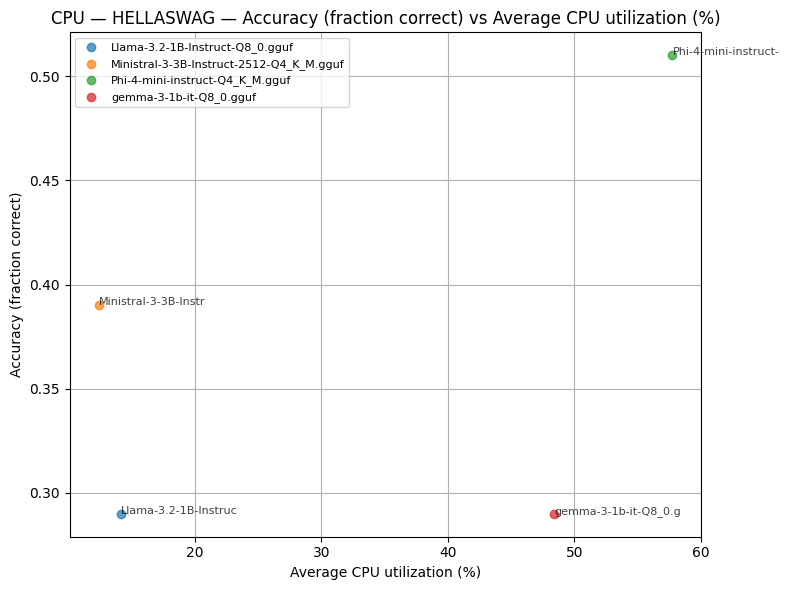

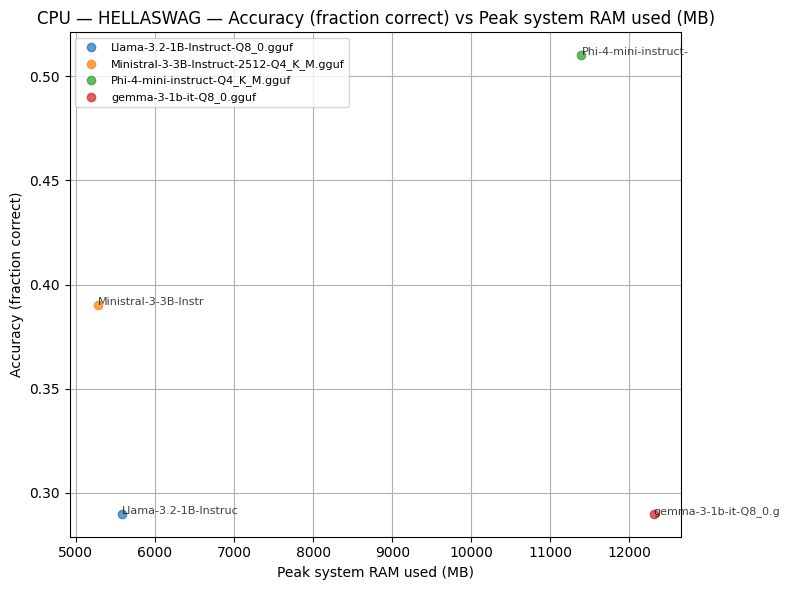

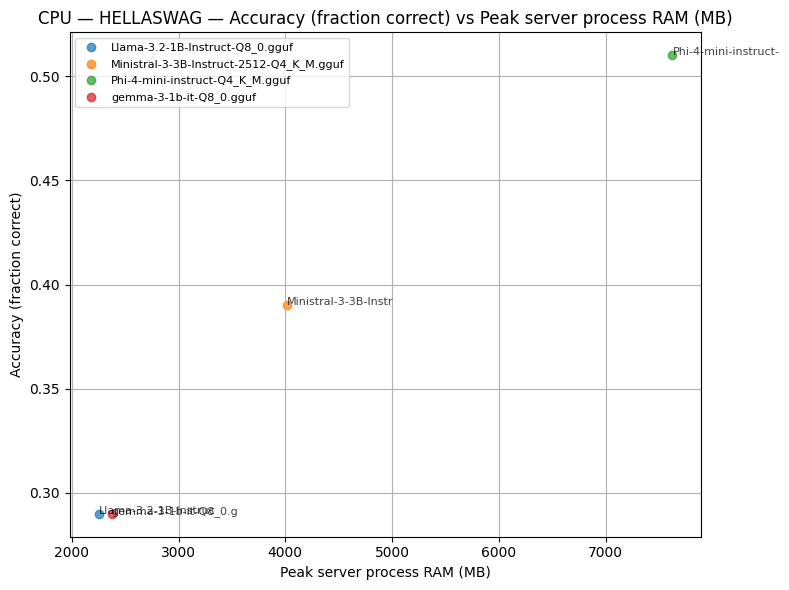

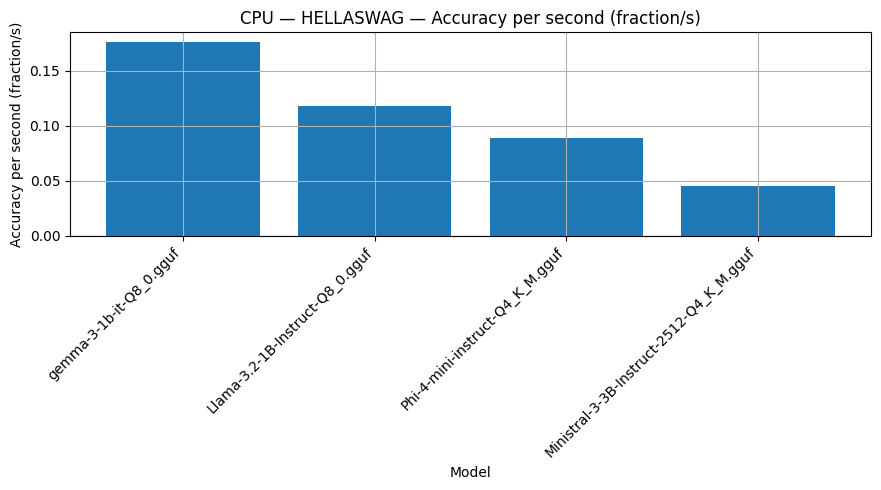


=== CPU / MMLU ===


,model,accuracy,latency_ms,ttft_ms,tokens_per_sec,sustained_tokens_per_sec,samples_per_sec,cpu_percent_avg,cpu_percent_peak,ram_used_mb_peak,process_ram_mb_peak,accuracy_per_second
1,Ministral-3-3B-Instruct-2512-Q4_K_M.gguf,0.62,6390.64560,6268.5256,8.2628,0.1555,0.1555,12.50810,33.1,5643.690,4399.390,0.097017
2,Phi-4-mini-instruct-Q4_K_M.gguf,0.54,3988.11155,3714.4522,9.7631,0.6259,0.2488,57.27385,95.6,9219.885,6685.605,0.135448
0,Llama-3.2-1B-Instruct-Q8_0.gguf,0.38,1820.87560,1764.2507,18.1393,0.5437,0.5383,14.57600,50.8,11004.540,2020.260,0.208691
3,gemma-3-1b-it-Q8_0.gguf,0.31,1110.47670,1030.4613,13.5681,0.8775,0.8775,48.45000,84.6,11657.050,1995.570,0.279159


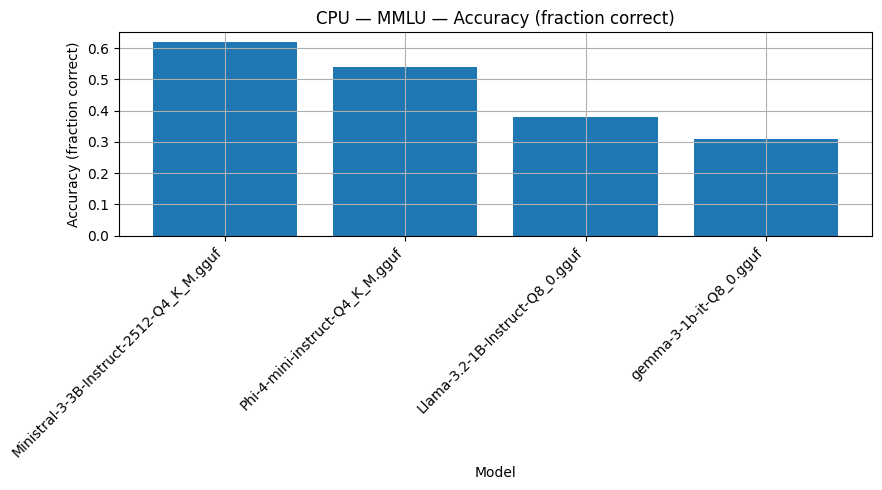

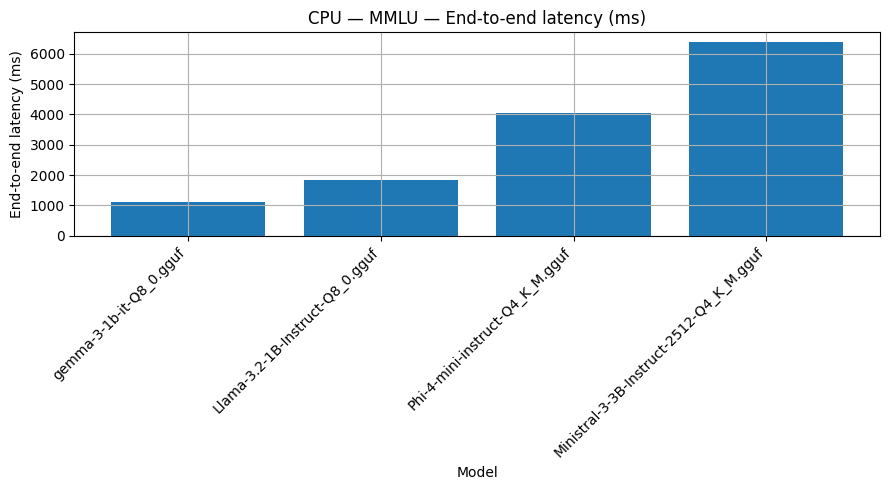

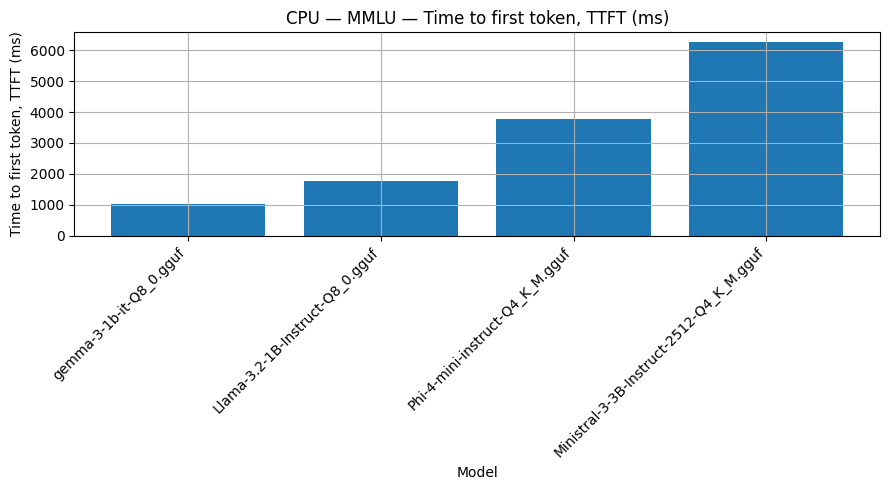

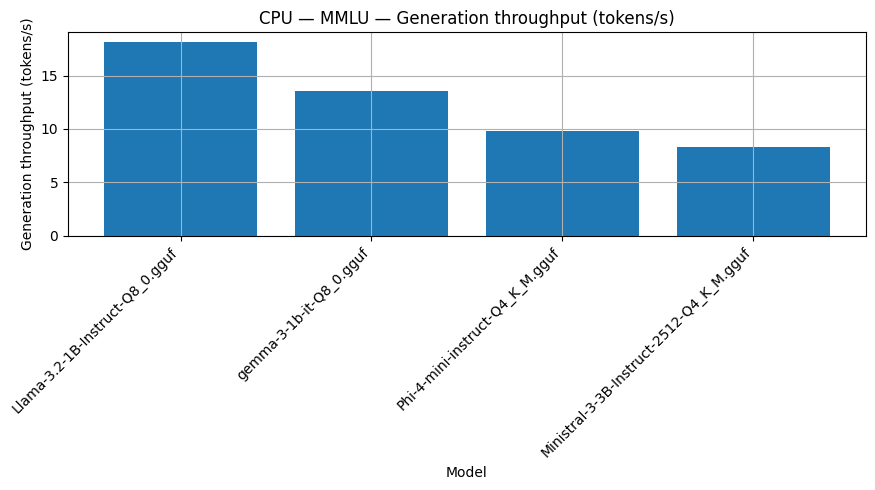

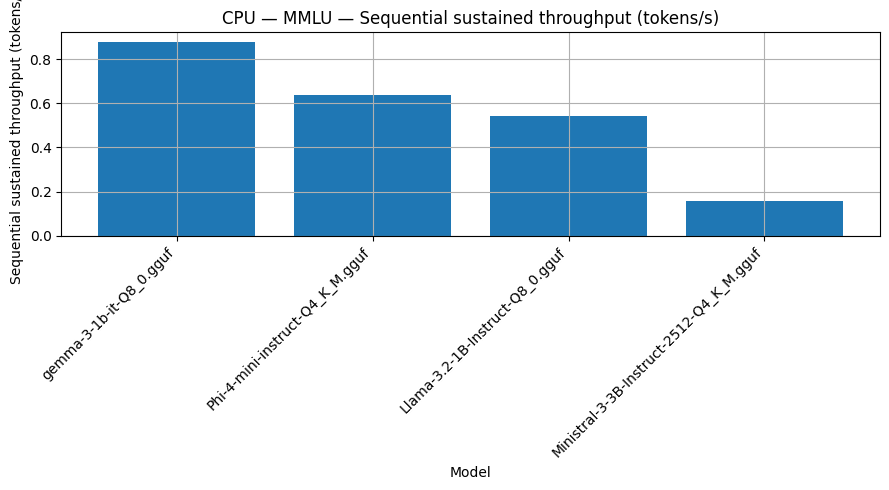

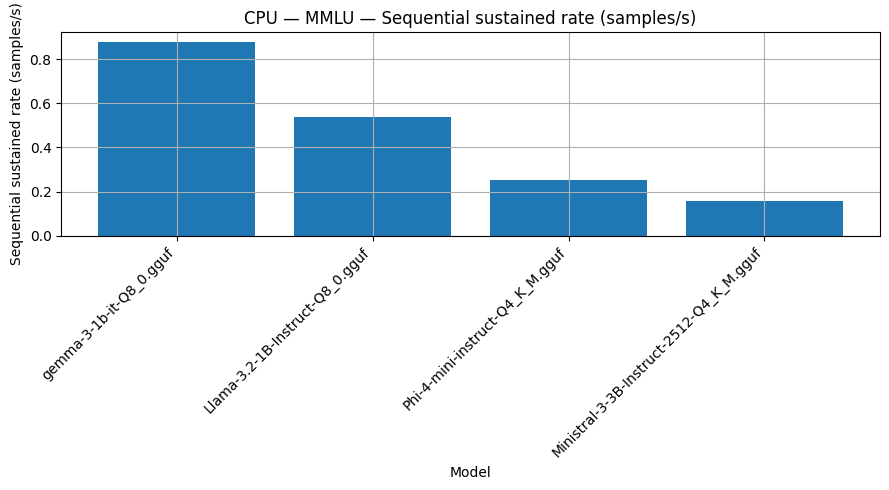

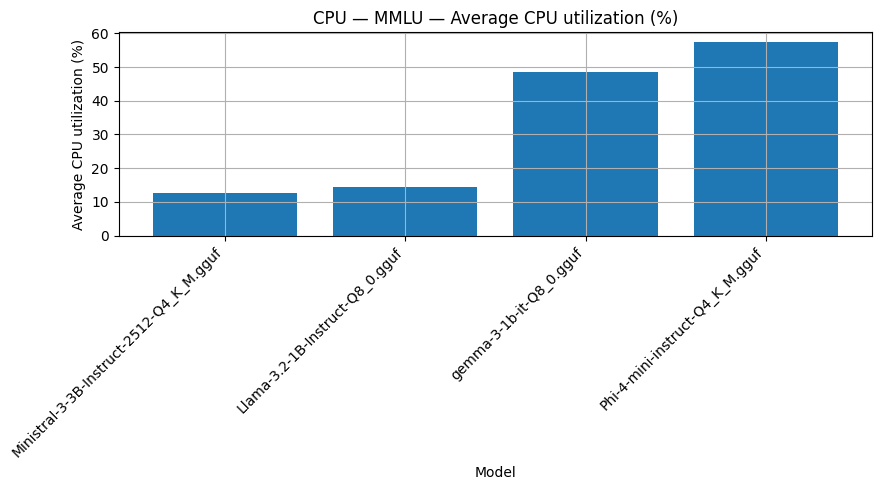

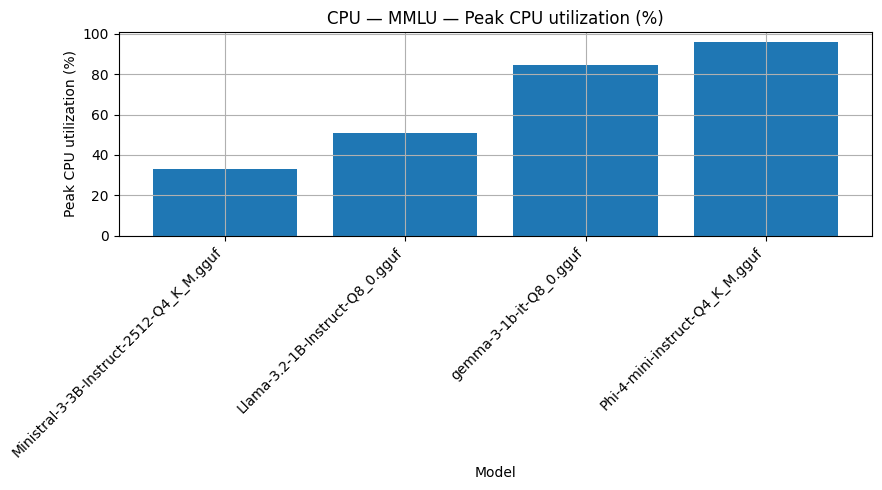

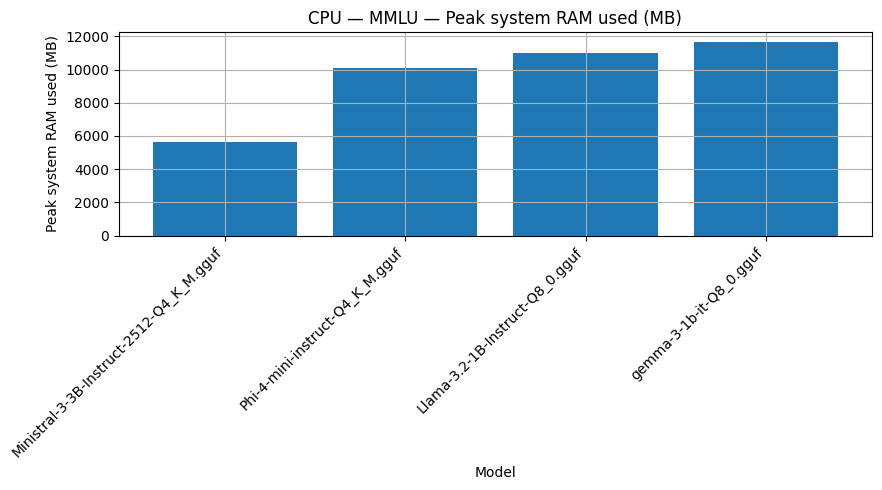

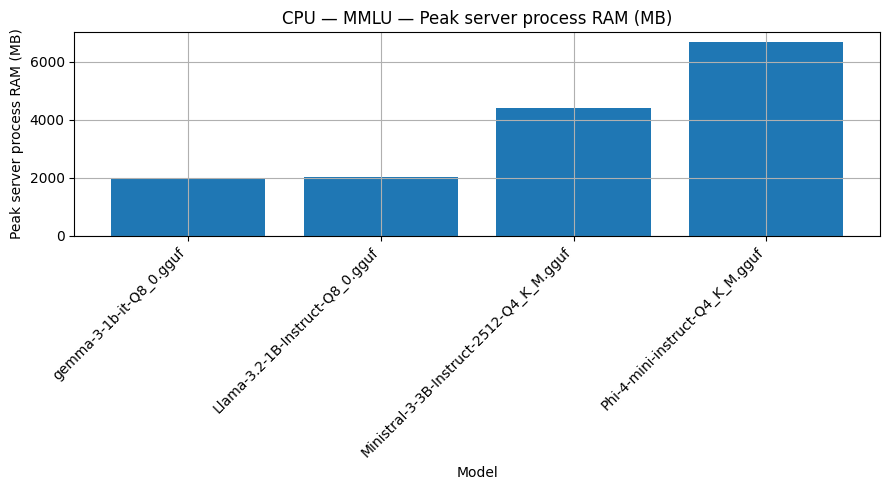

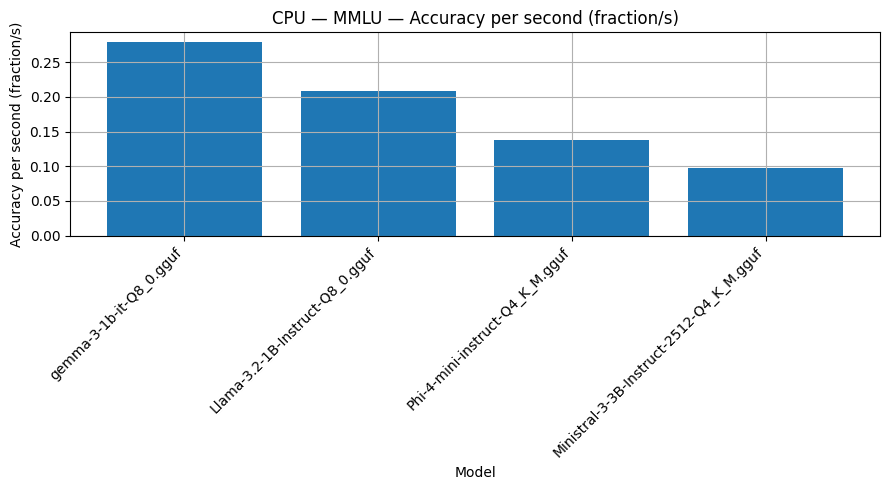

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


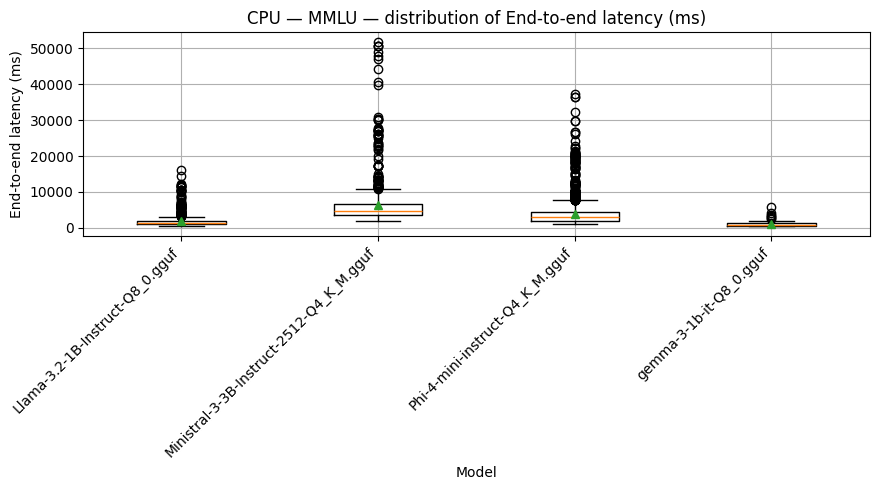

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


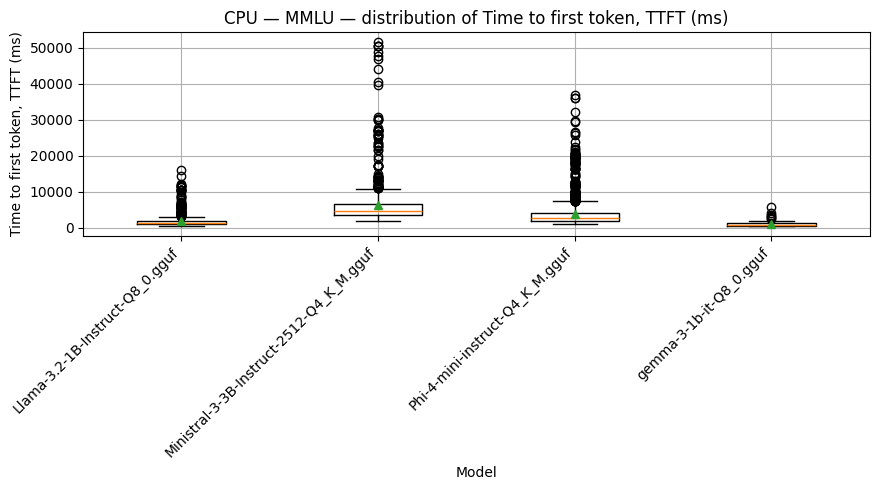

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


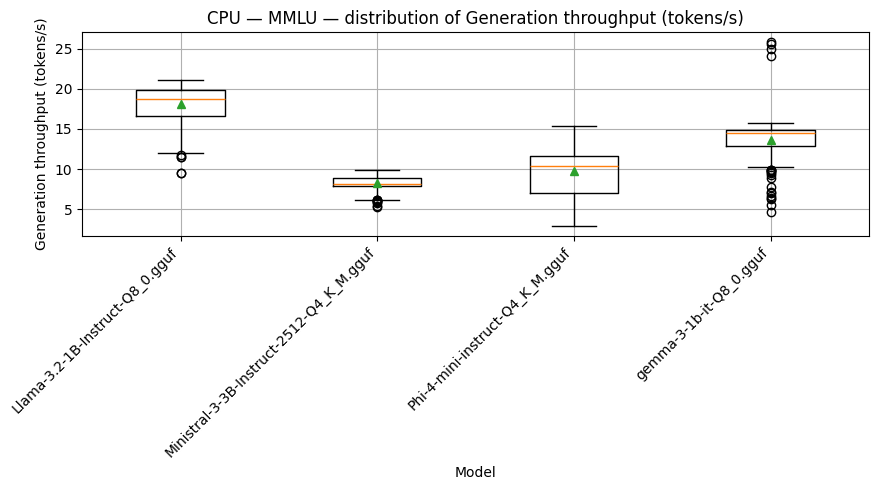

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


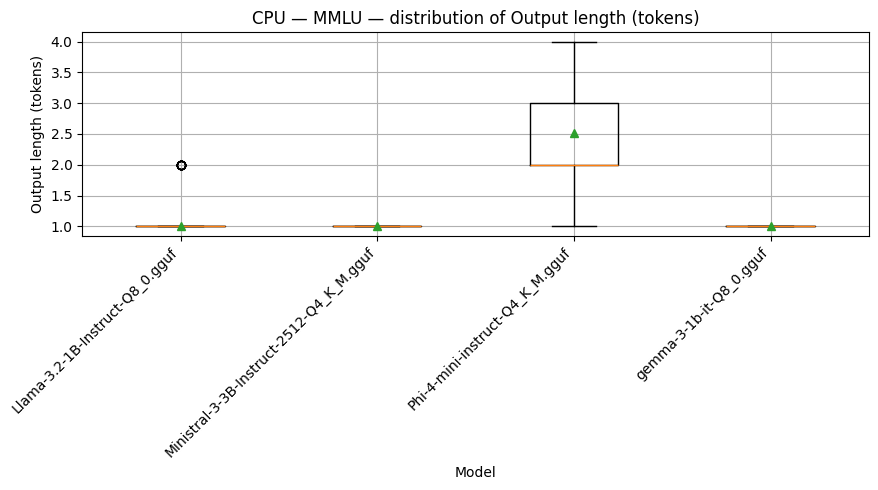

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


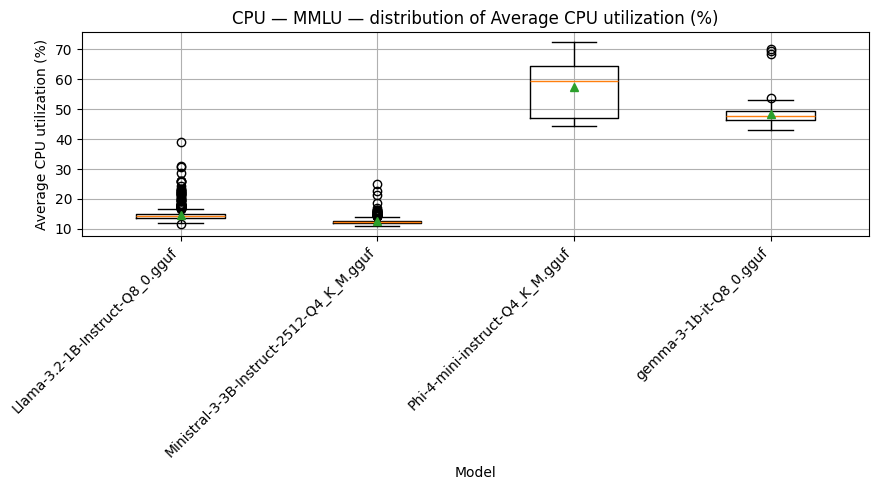

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


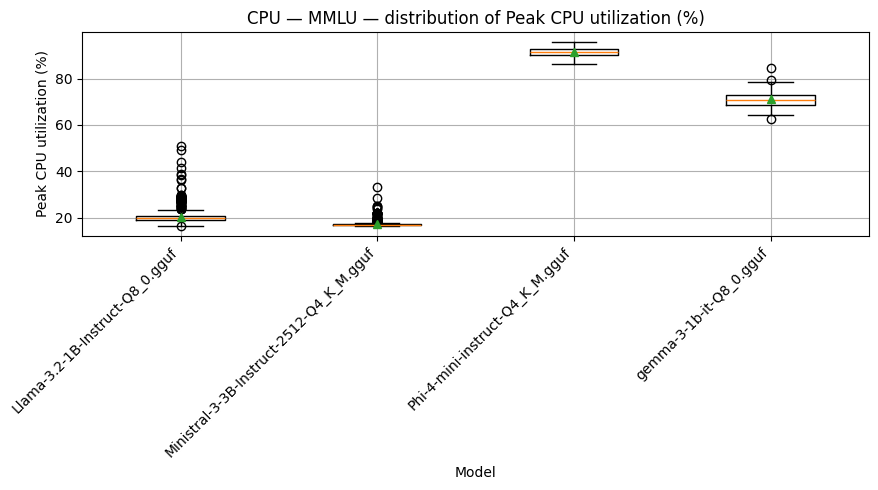

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


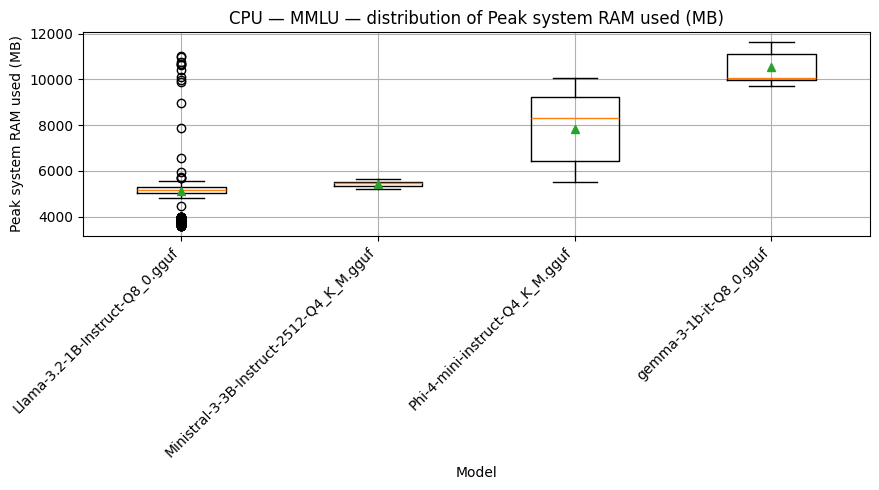

/tmp/ipykernel_1358661/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


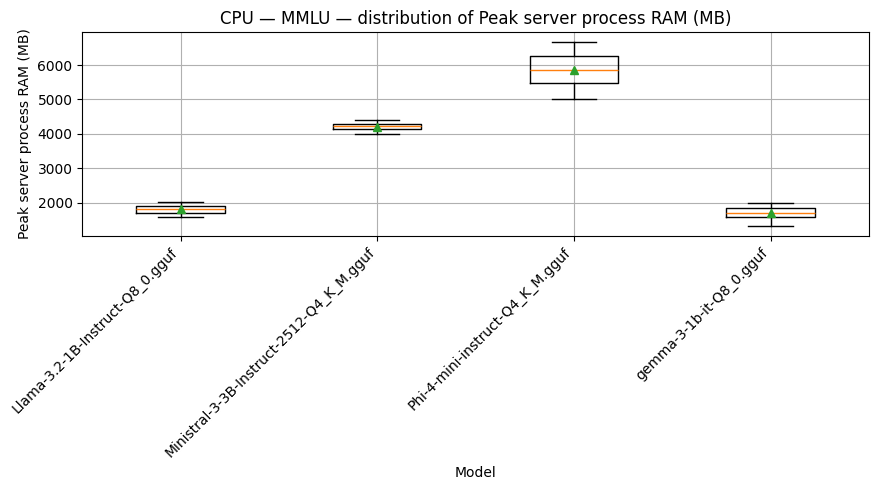

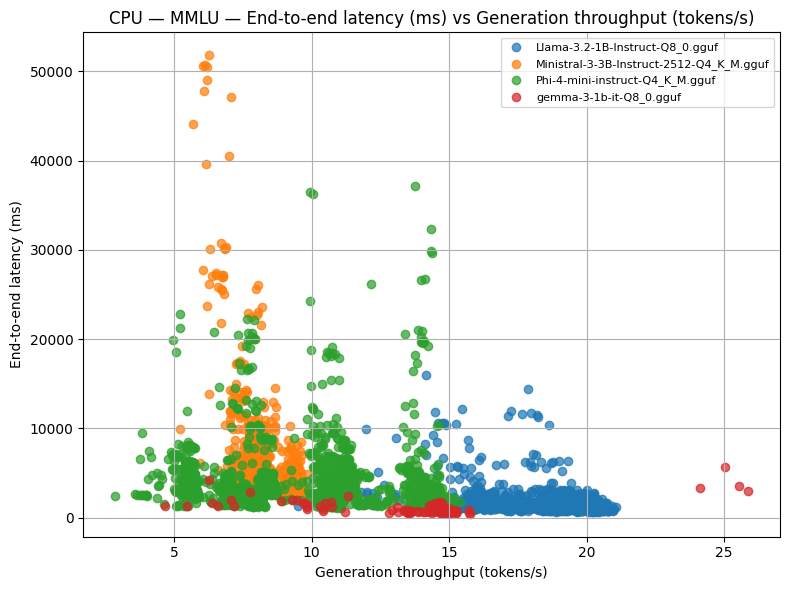

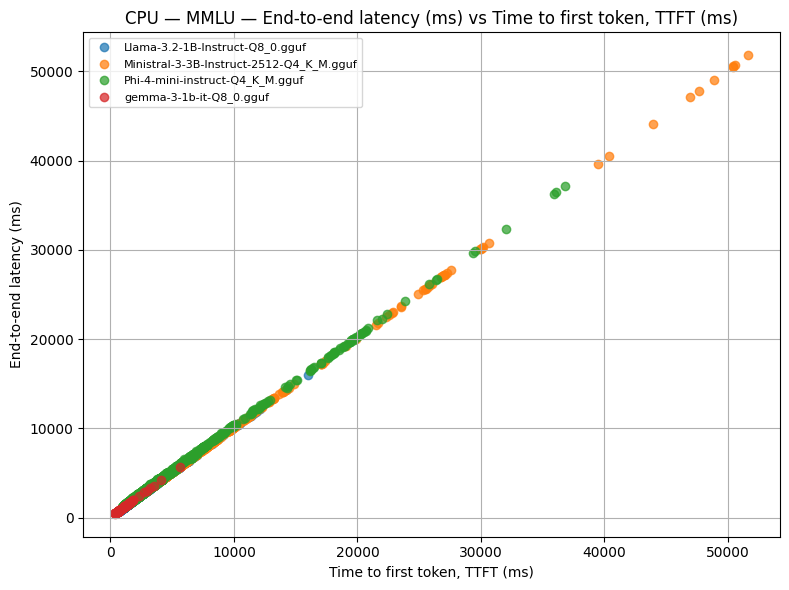

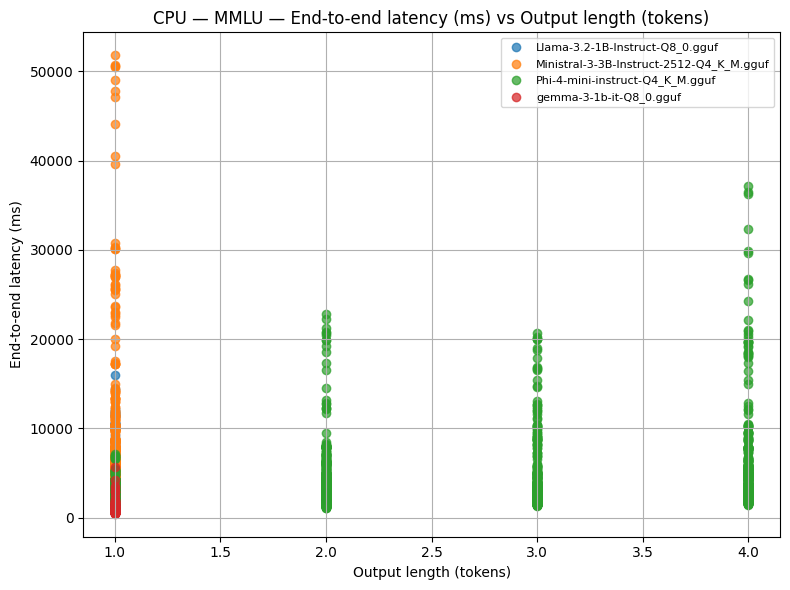

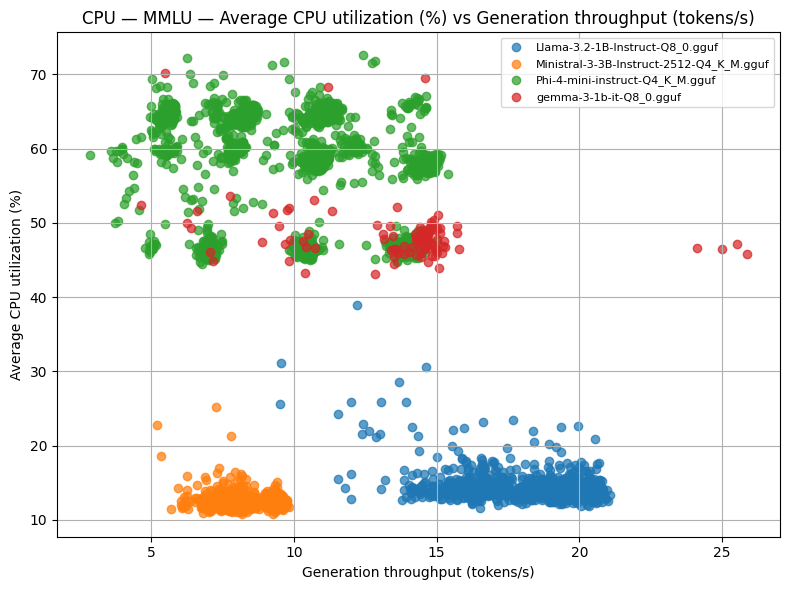

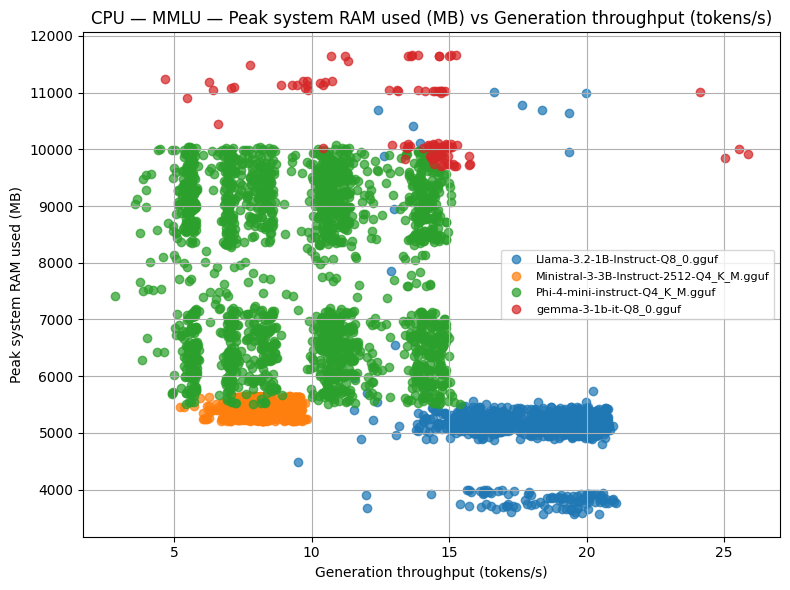

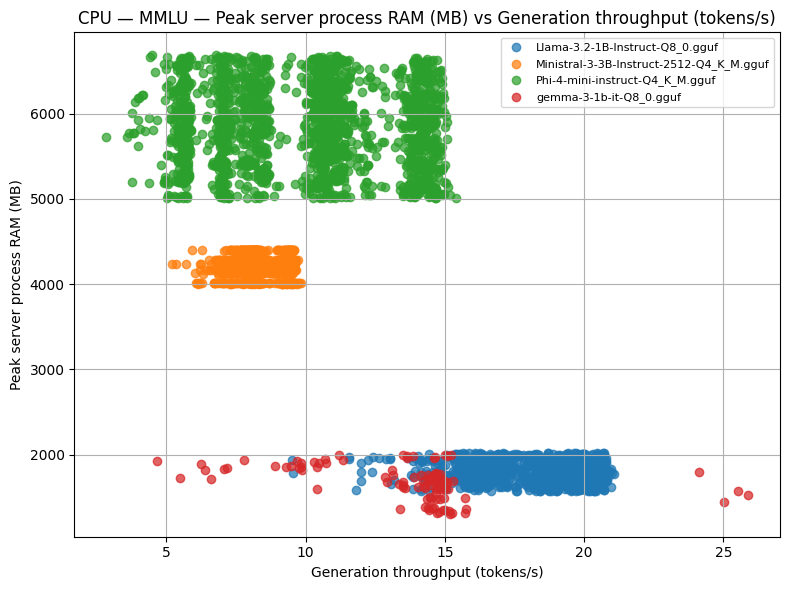

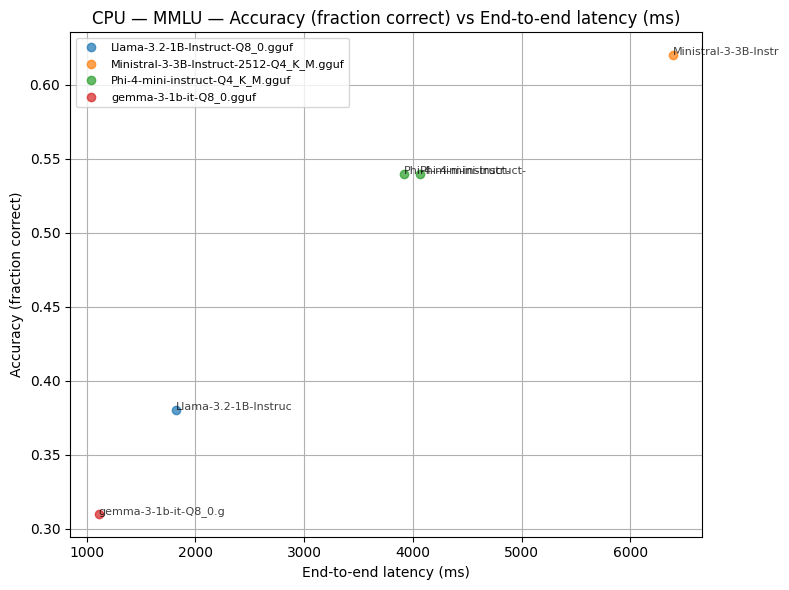

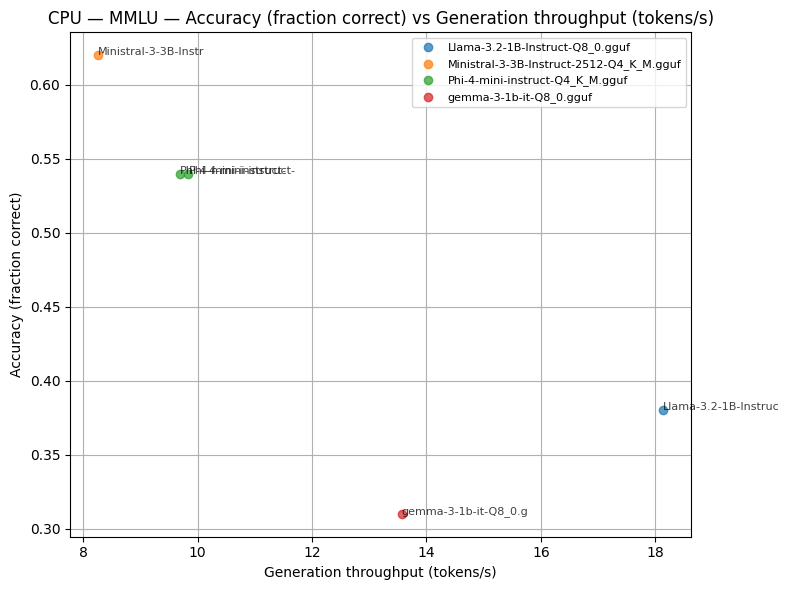

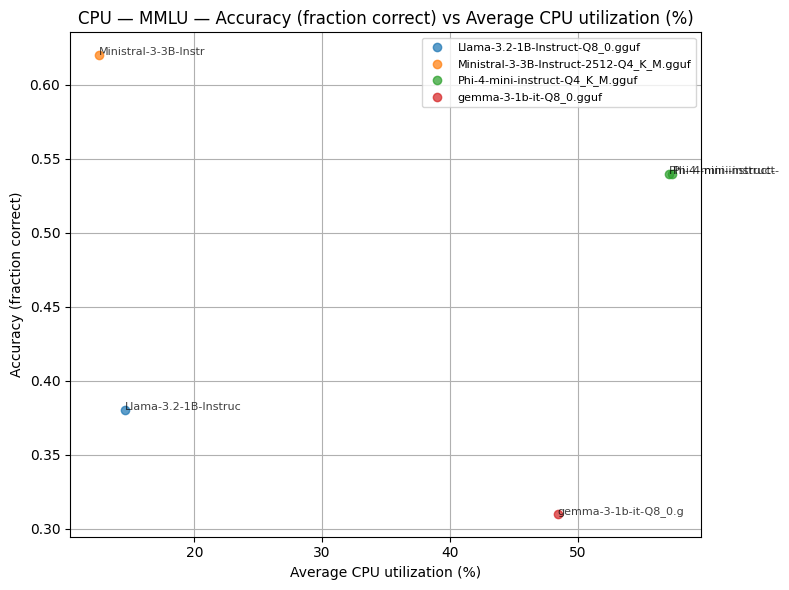

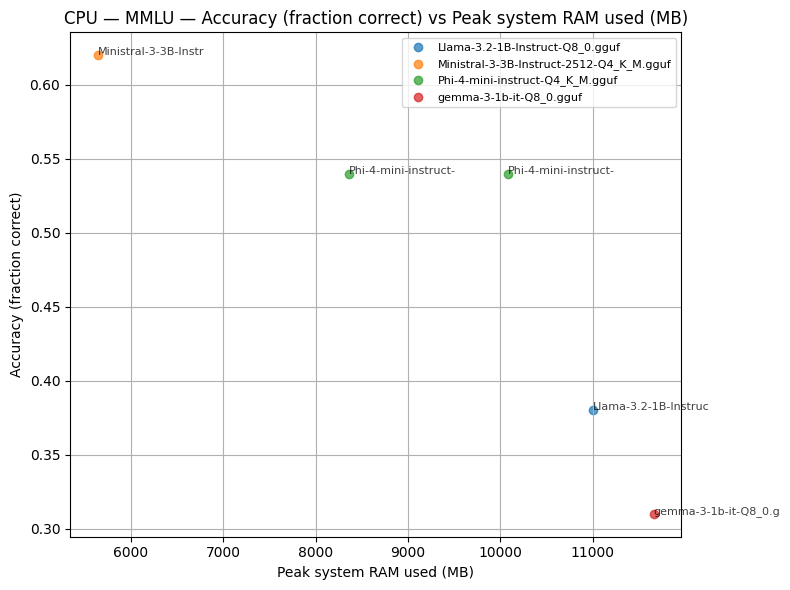

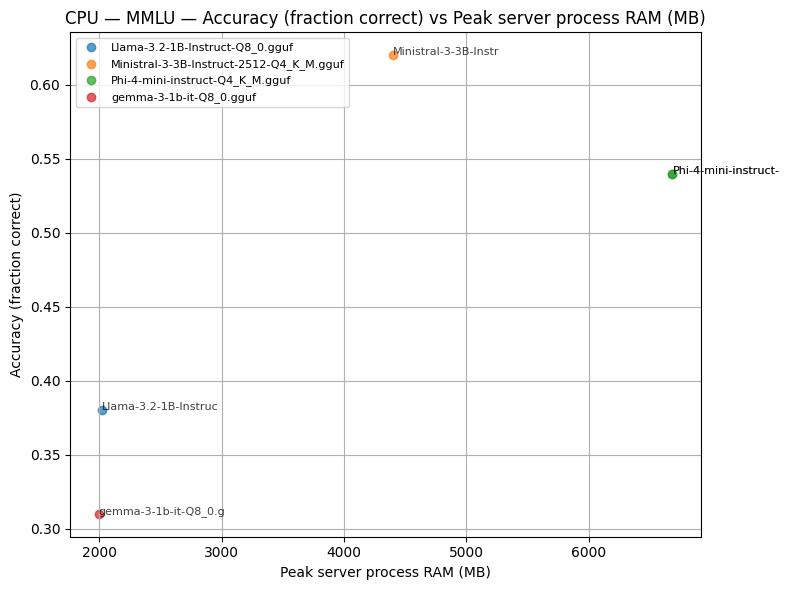

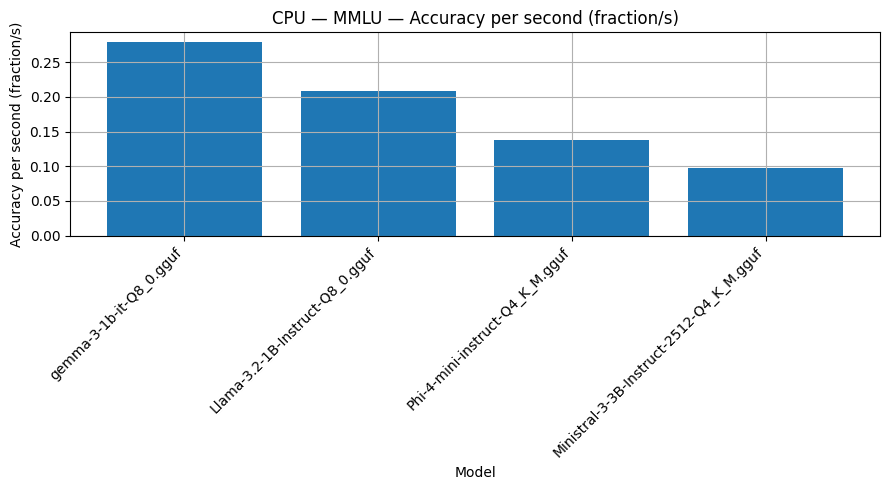

In [5]:
# Individual platform analysis
platform = next(iter(platform_data))
d = platform_data[platform]
summary = d["summary"]
samples = d["samples"]
traces = d["traces"]

datasets = datasets_in(summary, samples, traces)
print("Datasets:", datasets)

# Metric catalog available in this notebook
available_summary_metrics = available_metrics(summary, SUMMARY_METRICS_COMMON)
available_sample_metrics = available_metrics(samples, SAMPLE_METRICS_COMMON)
available_trace_metrics = available_metrics(traces, TRACE_METRICS_COMMON)
print("Summary metrics:", available_summary_metrics)
print("Sample metrics:", available_sample_metrics)
print("Trace metrics:", available_trace_metrics)

for dataset in datasets:
    print(f"\n=== {platform.upper()} / {dataset.upper()} ===")
    display(ranking_table(summary, dataset, SUMMARY_METRICS_COMMON, group_cols=("model",)))

    # Summary bars, including accuracy when present.
    for metric in available_summary_metrics:
        if dataset == "dolly" and metric.startswith("accuracy"):
            continue
        bar_metric_by_model(summary, platform, dataset, metric, x_col="model", out_dir=FIGURES_DIR)

    # Sample-level distributions.
    for metric in available_sample_metrics:
        boxplot_metric_by_model(samples, platform, dataset, metric, x_col="model", out_dir=FIGURES_DIR)

    # Performance/cost scatter plots.
    scatter_pairs = [
        ("tokens_per_sec", "latency_ms"),
        ("ttft_ms", "latency_ms"),
        ("output_tokens", "latency_ms"),
        ("tokens_per_sec", "cpu_percent_avg"),
        ("tokens_per_sec", "ram_used_mb_peak"),
        ("tokens_per_sec", "process_ram_mb_peak"),
        ("tokens_per_sec", "temp_c_avg"),
        ("tokens_per_sec", "gpu_util_percent_avg"),
        ("tokens_per_sec", "vram_used_mb_peak"),
        ("tokens_per_sec", "power_w_avg"),
        ("tokens_per_sec", "energy_j"),
        ("power_w_avg", "energy_j"),
    ]
    for x, y in scatter_pairs:
        scatter_metric_pair(samples, platform, dataset, x, y, group_col="model", out_dir=FIGURES_DIR)

    # Accuracy-qualified cost analysis for scored datasets only.
    if dataset in DATASETS_WITH_ACCURACY and metric_available(summary, "accuracy"):
        for x in ["latency_ms", "tokens_per_sec", "cpu_percent_avg", "ram_used_mb_peak", "process_ram_mb_peak", "temp_c_avg", "gpu_util_percent_avg", "vram_used_mb_peak", "power_w_avg", "energy_j", "energy_per_token_j"]:
            scatter_metric_pair(summary, platform, dataset, x, "accuracy", group_col="model", out_dir=FIGURES_DIR, annotate=True)
        for metric in ["accuracy_per_second", "accuracy_per_joule"]:
            if metric_available(summary, metric):
                bar_metric_by_model(summary, platform, dataset, metric, x_col="model", out_dir=FIGURES_DIR)

    # JSON trace plots.
    for metric in available_trace_metrics:
        trace_metric_plot(traces, platform, dataset, metric, group_col="model", out_dir=FIGURES_DIR)

In [6]:
# Optional VS Code export helper. Run this cell after saving the notebook file.
from pathlib import Path
notebook_name = Path(globals().get("__vsc_ipynb_file__", "visualization_notebook.ipynb"))
print("VS Code export command:")
print(f"jupyter nbconvert --to html --execute {notebook_name}")

VS Code export command:
jupyter nbconvert --to html --execute /home/stephane/llm-experiments/notebooks/02_visualization_cpu_fixed.ipynb
